In [72]:
# Cell 0: choose where everything is stored (data, caches, outputs all live under ROOT)
import os, sys
from pathlib import Path
USE_DRIVE = True                   # True: Google Drive (survives disconnects). False: local folder (Colab: /content, lost on disconnect)
DRIVE_DIR = "conformal_budget_mlqa"     # created automatically under MyDrive; no manual step needed
IN_COLAB = "google.colab" in sys.modules or os.path.isdir("/content/sample_data")
if IN_COLAB and USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive"); ROOT = Path("/content/drive/MyDrive") / DRIVE_DIR
    except Exception as e:
        print("Drive mount failed, using /content instead (files will be lost on disconnect):", e); ROOT = Path("/content") / DRIVE_DIR
elif IN_COLAB: ROOT = Path("/content") / DRIVE_DIR
else: ROOT = Path.cwd()
ROOT.mkdir(parents=True, exist_ok=True); os.chdir(ROOT)
print("ROOT =", ROOT, "| Colab:", IN_COLAB, "| Drive:", USE_DRIVE and IN_COLAB)

Drive mount failed, using /content instead (files will be lost on disconnect): Error: credential propagation was unsuccessful
ROOT = /content/conformal_budget_mlqa | Colab: True | Drive: True


# Conformal Token Budgets for Cross-Lingual Retrieval-Augmented Generation (MLQA, answer-level evidence)

**Does a context-token budget calibrated with split conformal prediction on English keep its coverage guarantee on Hindi?**

Authors: *[author names]* &nbsp;|&nbsp; Institution: *[department, university]* &nbsp;|&nbsp; Supervisor: *[name]* &nbsp;|&nbsp; Date: *[date]*

**Abstract.** *[To be written after the final run. Suggested content: the question; data (MLQA English and Hindi: parallel questions, Wikipedia paragraphs, retrieval from the full set of MLQA paragraphs, evidence = the gold answer string occurs in the passage; token premium from FLORES-200); method (split conformal calibration of a token budget on the depth of the first relevant passage); the main numbers from the "Auto-drafted discussion" cell; the gate verdict; one sentence on limitations.]*

## 1. Problem and hypothesis

A retrieval-augmented generation system sends the top-ranked passages to a language model under a context budget measured in **tokens**. For a query $q$ let $d_1,\dots,d_K$ be the retrieved passages in rank order ($K=K_{\mathrm{RET}}$), let $\ell_j$ be the length of $d_j$ in tokens of a given tokenizer, and let $r^*(q)=\min\{j\le K : d_j \text{ is relevant}\}$. The **token depth** is

$$T(q)=\sum_{j=1}^{r^*(q)} (\ell_j + 4), \qquad T(q)=\infty \text{ if no relevant passage is in the top } K,$$

where 4 tokens are added per passage as formatting overhead. A budget $B$ *covers* $q$ if $T(q)\le B$, that is, if the first relevant passage fits inside the budget.

**Split conformal budget.** Given $n$ calibration items with depths $T_1,\dots,T_n$ and a miscoverage level $\alpha$, set $k=\lceil (n+1)(1-\alpha)\rceil$ and

$$B=T_{(k)} \quad (\text{the } k\text{-th smallest depth}), \qquad B=\infty \text{ if } k>n.$$

If calibration and test items are exchangeable, then $1-\alpha \le \Pr(T_{n+1}\le B) \le 1-\alpha + \tfrac{1}{n+1}$ (the upper bound holds when there are no ties).

**Hypothesis.** The guarantee requires exchangeability. English and Hindi depths are not exchangeable, because the same content costs more tokens in Hindi and because retrieval quality may differ. We test whether an English-calibrated budget keeps $1-\alpha$ coverage on Hindi. There are three consequences:

1. **Infeasibility.** If more than a fraction $\alpha$ of items have $T=\infty$, then $B=\infty$: the problem is limited by retrieval, not by the budget.
2. **Under-coverage under shift.** The coverage of the English budget on Hindi is $F_{HI}(F_{EN}^{-1}(1-\alpha))$ up to finite-sample error, and $|\Pr_{HI}(T\le B)-\Pr_{EN}(T\le B)|\le \sup_x|F_{EN}(x)-F_{HI}(x)|$ (the Kolmogorov–Smirnov distance), so the gap is bounded by how different the two depth distributions are.
3. **Token price of translation.** If Hindi depths are about $\kappa$ times English depths, a Hindi-calibrated budget should satisfy $B_{HI}/B_{EN}\approx\kappa$, where $\kappa$ is the measured Hindi/English token ratio of the tokenizer (here measured on FLORES-200 parallel sentences, because MLQA Hindi contexts are not exact translations of the English ones).

The pre-committed decision rule (the *gate*, Section 6) is fixed before any result is seen: $\text{GAP\_MIN}=0.05$ and $\text{NEAR}=0.02$. The gap is defined as $(1-\alpha)-\text{coverage}$, so a positive gap means under-coverage.

In [73]:
# Constants (fixed before any result is seen). Do not tune on test results.
QUICK = False                      # True: 200-query smoke test; False: full run
N_QUICK, N_FULL = 200, 10**6       # MLQA: N_FULL = all usable aligned questions (the cap is never reached)
N_CPU_CAP = 40                     # only used for a QUICK smoke test without GPU
MAX_HOURS = 2.0                    # embedding time budget; N is reduced if the ETA exceeds it
SEED = 0
SEEDS = (SEED, SEED + 1, SEED + 2) # SEED is the pre-committed one; the others are robustness
K_RET, POOL_BM25, MAXLEN = 30, 100, 256
OVERHEAD = 4                       # passage cost = tokens + 4
R = 200                            # repeated group splits
ALPHAS = (0.05, 0.1, 0.2)
KS_FEW = (10, 25, 50, 100, 200)
TOPK_BASE = (1, 3, 5, 10)
FIXED_BUDGETS = (256, 512, 1024, 2048)
GAP_MIN, NEAR = 0.05, 0.02         # gate thresholds (pre-committed)
GATE_ALPHA = 0.1
N_BOOT, SPLITS_PER_BOOT = 500, 10
TOKS = ("cl100k", "o200k", "qwen3", "bge-m3")

INCLUDE_REL_IN_POOL = True         # MLQA: the pool is the full set of paragraph pairs, so every relevant passage is in it; there is no BM25 pool
RUN_NOREL_ROBUSTNESS = False       # MLQA: no BM25-only pool exists, so no pool comparison
USE_RERANKER = False               # True: rerank top RERANK_TOP dense candidates with bge-reranker-v2-m3
RERANK_TOP, RERANK_MODEL = 50, "BAAI/bge-reranker-v2-m3"
EXTRA_LANGS = ("arabic",)          # optional non-Indic third language; dropped automatically if < MIN_ALIGNED_EXTRA aligned questions.
                                   # NOTE: ids must exist in EVERY language used, so Arabic shrinks the English-Hindi sample (see cell 9 output)
SYNTHETIC_TEST = False             # offline pipeline test on fake data (never for the real run)
RUN_MLQA = False                   # optional last-but-one cell
MLQA_URL = "https://dl.fbaipublicfiles.com/MLQA/MLQA_V1.zip"
MLQA_SPLITS = ("dev", "test")     # monolingual files of both splits are combined
MIN_ALIGNED_EXTRA = 300            # an extra language is used only if at least this many questions are aligned across all languages
REL_MODE = "own_context"     # "answer_in_context": every passage containing a gold answer string (+ own pair); "own_context": own pair only (sensitivity)
FLORES_SPLIT = "devtest"           # FLORES-200 split used for the token premium kappa (1012 parallel sentences)
MIN_FREE_GB = 4                   # stop if less space is free at ROOT; real need is ~2-3 GB, lower this (e.g. 5) if your Drive is nearly full

LANGS = ("english", "hindi") + tuple(EXTRA_LANGS)
TEST_LANGS = LANGS[1:]

In [74]:
import sys, subprocess, importlib, time, math, json, gzip, tarfile, io, re, random, warnings, zipfile, pickle, zlib, shutil
import torch
CUDA = torch.cuda.is_available(); DEV = "cuda" if CUDA else "cpu"
assert CUDA or QUICK or SYNTHETIC_TEST, ("No CUDA GPU found. In Colab choose Runtime > Change runtime type > T4 GPU, "
                                         "then run again (QUICK=False requires a GPU).")
def _need(mod):
    try: importlib.import_module(mod)
    except ImportError: subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", mod])
from importlib import metadata as _md
def _ver(p):
    try: return tuple(int(x) for x in re.findall(r"\d+", _md.version(p))[:2])
    except Exception: return None
if _ver("torch") and _ver("transformers") and _ver("torch") < (2, 6) and _ver("transformers") >= (5, 0):
    print("transformers>=5 needs torch>=2.6; installing transformers<5 (restart the kernel if transformers was already imported)")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "transformers>=4.45,<5"])
for m in ("numpy", "pandas", "pyarrow", "requests", "tqdm", "scipy", "matplotlib", "huggingface_hub", "transformers", "tiktoken", "sentencepiece"):
    _need(m)
import numpy as np, pandas as pd, requests, tiktoken, transformers, huggingface_hub, matplotlib, scipy, pyarrow
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DATA = ROOT / ("data_synth" if SYNTHETIC_TEST else "data"); OUT = ROOT / ("outputs_synth" if SYNTHETIC_TEST else "outputs")
DATA.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)
N_QUERIES = int(os.environ.get("N_OVERRIDE", 0)) or (N_QUICK if QUICK else N_FULL)
if CUDA: print("GPU:", torch.cuda.get_device_name(0), f"({torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GiB)")
elif not SYNTHETIC_TEST:
    N_QUERIES = min(N_QUERIES, N_CPU_CAP); print(f"NO CUDA GPU found -> CPU smoke test; N_QUERIES cut to {N_QUERIES}")
try:
    free = shutil.disk_usage(ROOT).free / 1e9; print(f"free disk space at ROOT: {free:.1f} GB")
    assert free >= MIN_FREE_GB or SYNTHETIC_TEST, f"Only {free:.1f} GB free at {ROOT}; MIN_FREE_GB = {MIN_FREE_GB}. Free some space, or lower MIN_FREE_GB (the run itself needs about 2-3 GB)."
except AssertionError: raise
except Exception as e: print("could not read free disk space:", e)
print("N_QUERIES =", N_QUERIES, "| QUICK =", QUICK, "| langs =", LANGS, "| include_rel_in_pool =", INCLUDE_REL_IN_POOL)
for m in (np, pd, requests, torch, tiktoken, transformers, huggingface_hub, matplotlib, scipy, pyarrow):
    print(f"{m.__name__:16s}{m.__version__}")
print("python", sys.version.split()[0])

GPU: Tesla T4 (14.6 GiB)
free disk space at ROOT: 116.1 GB
N_QUERIES = 1000000 | QUICK = False | langs = ('english', 'hindi', 'arabic') | include_rel_in_pool = True
numpy           2.4.6
pandas          2.2.3
requests        2.32.4
torch           2.11.0+cu130
tiktoken        0.14.0
transformers    5.22.0
huggingface_hub 1.33.0
matplotlib      3.10.0
scipy           1.16.3
pyarrow         23.0.1
python 3.13.16


## 2. Data

**Corpus.** MLQA (`facebook/mlqa`, licence CC-BY-SA 3.0) is an extractive QA benchmark built on Wikipedia. We use the *monolingual* files (context and question in the same language) of the dev and test splits combined, read directly from `MLQA_V1.zip` (no `load_dataset`). English is the calibration language, Hindi the primary test language, and Arabic an optional third, non-Indic language (`EXTRA_LANGS`).

**Parallel questions, non-identical contexts.** MLQA questions are professionally translated and share the same id across languages, so questions are aligned by id; only ids present in *every* language used are kept. The contexts are the corresponding paragraphs of each language's Wikipedia: they cover the same content but are **not exact translations** of the English paragraph.

**Passages and pool.** A passage is a context paragraph. A *pair* $k$ is the tuple of language contexts of a question, deduplicated by text; pid $= k$ is shared across languages and `ptext[lang][k]` is that language's paragraph. The candidate pool of **every** question is the **full set of pairs** (the whole MLQA corpus in that language), so retrieval is from a real corpus of a few thousand paragraphs rather than a per-query candidate list. The retrieved list is the top $K_{\mathrm{RET}}=30$ by BGE-M3 cosine similarity, computed separately in each language.

**Evidence (answer level).** A passage is *evidence* for a question in language $l$ if its language-$l$ text contains a gold answer string of the question in language $l$, after normalisation (Unicode NFC, lowercase, whitespace collapsed; zero-width characters removed for Hindi). The question's own pair is always included. With `REL_MODE = "own_context"` only the own pair counts (sensitivity analysis). Short answers (numbers, years, names) often occur in other paragraphs too; the share of such questions is printed. Hindi questions whose Hindi answer is not found in their own Hindi context are dropped and logged in `outputs/dropped_rows.csv`; `outputs/qid_map.csv` maps the integer qids to MLQA ids, pairs and groups.

**Size.** The dataset is small. As checked on the released zip: English–Hindi gives 5,425 aligned questions over 4,639 unique (English, Hindi) context pairs and 4,482 unique English contexts; requiring Arabic as well leaves 2,017 questions, 1,736 pairs and 1,642 English contexts. The exact numbers of this run are printed in the data cells.

**Groups.** Questions that share an English context form one group, so they are never split between calibration and test.

**Token premium.** Because the contexts are not exact translations, $\kappa$ is measured on FLORES-200 *devtest* (the same 1,012 sentences in every language): $\kappa$ = mean tokens(language) / mean tokens(English), per tokenizer. The passage-based ratio is still reported (`kappa_passage`).

**Licences (to be verified).** MLQA: CC-BY-SA 3.0. FLORES-200: *[to be verified]*. BGE-M3 and bge-reranker-v2-m3: *[to be verified]*. Tokenizers (tiktoken, Qwen3, XLM-R): *[to be verified]*.

## Pre-registered prediction (written before running on MLQA)

**Prediction.** At $\alpha \in \{0.2, 0.25, 0.3, 0.4\}$, the observed budget ratio $B_{hi}/B_{en}$ (Hindi-calibrated over English-calibrated conformal budget) is within 10% of $\kappa_{hi}\times\rho_{hi}$ for **all four tokenizers**. Here $\kappa_{hi}$ is the FLORES-200 Hindi/English token premium of the tokenizer and $\rho_{hi}$ is the ratio of the same conformal quantile of the *rank* depth (number of passages needed to reach the first evidence passage; no tokenizer involved).

**How it is read.** From `decomposition.csv` (cell *EXTRA 1*), rows with `lang = hindi`: the prediction holds if `obs_over_kappa_rho` is in [0.90, 1.10] for all 4 tokenizers × 4 values of $\alpha$ (16 rows). Any row outside this range, or missing (fewer than 20 splits with finite budgets), is reported as a **failure**.

**Retrieval-limited gate.** The pool is the full MLQA corpus, so retrieval may miss the evidence for more than 10% of questions. The unconditional gate at $\alpha = 0.1$ may then be retrieval-limited ($B=\infty$ in most splits); in that case the conditional-coverage cell (*EXTRA 2*, coverage given that evidence is retrieved) is the **primary analysis**, and the gate verdict is reported but not interpreted as a test of the shift. The gate constants are unchanged.

In [75]:
# Download and parse MLQA (monolingual files, dev + test). No load_dataset.
# Checked layout: MLQA_V1/{dev,test}/{split}-context-{c}-question-{c}.json, SQuAD style:
#   data[].paragraphs[].context, data[].paragraphs[].qas[].{id, question, answers[{text, answer_start}]}
# FLORES-200: dl.fbaipublicfiles.com/nllb/flores200_dataset.tar.gz, members ./flores200_dataset/devtest/{code}.devtest (1012 lines)
import unicodedata
MLQA_CODE = {"english": "en", "hindi": "hi", "arabic": "ar", "german": "de", "spanish": "es", "vietnamese": "vi", "chinese": "zh"}
FLORES_CODE = {"english": "eng_Latn", "hindi": "hin_Deva", "arabic": "arb_Arab", "german": "deu_Latn", "spanish": "spa_Latn", "vietnamese": "vie_Latn", "chinese": "zho_Hans"}
FLORES_URL = "https://dl.fbaipublicfiles.com/nllb/flores200_dataset.tar.gz"
assert all(l in MLQA_CODE for l in LANGS), f"no MLQA file for {[l for l in LANGS if l not in MLQA_CODE]}"
def member(split, c): return f"MLQA_V1/{split}/{split}-context-{c}-question-{c}.json"

_ZW = dict.fromkeys(map(ord, "\u200b\u200c\u200d\u2060\ufeff"), None)
def norm(s, lang):
    s = unicodedata.normalize("NFC", s)
    if lang == "hindi": s = s.translate(_ZW)
    return re.sub(r"\s+", " ", s.lower()).strip()

def make_fake_mlqa(zp):
    """Tiny MLQA-shaped zip (SQuAD JSON, parallel ids, one context per paragraph, answers = spans), SYNTHETIC_TEST only."""
    rg = np.random.default_rng(123); V = 800
    W = ["".join(rg.choice(list("bcdfghklmnprstvz")) + rg.choice(list("aeiou")) for _ in range(int(rg.integers(2, 4)))) for _ in range(V)]
    BASE = {"hindi": 0x0905, "arabic": 0x0621}
    paras = []
    for k in range(120):                                   # 120 paragraphs, 1-3 questions each
        ws = [int(x) for x in rg.integers(0, V, int(rg.integers(40, 90)))]; qs = []
        for m in range(int(rg.integers(1, 4))):
            a0 = int(rg.integers(0, len(ws) - 3)); qs.append((f"q{k:03d}{m}", ws[a0: a0 + int(rg.integers(1, 3))], [int(x) for x in rg.choice(ws, 4)]))
        paras.append((ws, qs))
    with zipfile.ZipFile(zp, "w") as z:
        for l in LANGS:
            tr = (lambda w, b=BASE[l]: "".join(chr(b + ord(x) - 97) for x in w)) if l in BASE else (lambda w: w)
            T = lambda ids: " ".join(tr(W[x]) for x in ids)
            for si, s in enumerate(MLQA_SPLITS):
                data = []
                for k, (ws, qs) in enumerate(paras):
                    if k % len(MLQA_SPLITS) != si: continue
                    ctx = T(ws); qas = []
                    for qid, ans, qw in qs:
                        if l == "english" and qid == "q0000": continue                      # id missing in English -> not aligned
                        a = T(ans); q = T(qw + ans[:1])
                        if l == "hindi" and qid == "q0010": a = tr("zzzz")                   # Hindi answer absent from own context -> dropped
                        if l == "hindi" and qid == "q0020": q = " "                          # empty question -> dropped
                        qas.append({"id": qid, "question": q, "answers": [{"text": a, "answer_start": max(ctx.find(a), 0)}]})
                    data.append({"title": f"t{k}", "paragraphs": [{"context": ctx, "qas": qas}]})
                z.writestr(member(s, MLQA_CODE[l]), json.dumps({"version": "1.0", "data": data}, ensure_ascii=False))

def load_flores(langs, optional=()):
    """FLORES-200 sentences {lang: [str]} (parallel across languages), cached as json. None if a required language is missing."""
    f = DATA / f"flores200_{FLORES_SPLIT}.json"; d = json.load(open(f, encoding="utf-8")) if f.exists() else {}
    want = [l for l in (*langs, *optional) if l in FLORES_CODE and l not in d]
    if want:
        try:
            with requests.get(FLORES_URL, stream=True, timeout=120) as r:
                r.raise_for_status()
                with tarfile.open(fileobj=r.raw, mode="r|gz") as tf:
                    for m in tf:
                        for l in want:
                            if m.isfile() and m.name.endswith(f"/{FLORES_SPLIT}/{FLORES_CODE[l]}.{FLORES_SPLIT}"):
                                d[l] = tf.extractfile(m).read().decode("utf-8").rstrip("\n").split("\n")
            json.dump(d, open(f, "w", encoding="utf-8"), ensure_ascii=False)
        except Exception as e:
            print("FLORES-200 download failed:", type(e).__name__, str(e)[:200])
    if not all(l in d for l in langs): return None
    out = {l: d[l] for l in (*langs, *optional) if l in d}
    assert len({len(v) for v in out.values()}) == 1, f"FLORES files differ in length: { {l: len(v) for l, v in out.items()} }"
    return out

ZP = DATA / ("fake_MLQA_V1.zip" if SYNTHETIC_TEST else "MLQA_V1.zip")
if SYNTHETIC_TEST: make_fake_mlqa(ZP); print("SYNTHETIC_TEST: fake MLQA zip", ZP)
elif not ZP.exists():
    tmp = ZP.with_suffix(".part")
    with requests.get(MLQA_URL, stream=True, timeout=120) as r, open(tmp, "wb") as f:
        r.raise_for_status()
        for c in r.iter_content(1 << 20): f.write(c)
    os.replace(tmp, ZP)
print(f"{ZP.name}: {ZP.stat().st_size / 1e6:.1f} MB")
MLQ = {}                      # MLQ[lang]: one row per question (id, split, question, context, answers)
with zipfile.ZipFile(ZP) as z:
    names = set(z.namelist())
    for l in LANGS:
        rows = []
        for s in MLQA_SPLITS:
            m = member(s, MLQA_CODE[l]); assert m in names, f"{m} not in {ZP.name}"
            for a_ in json.load(z.open(m))["data"]:
                for p in a_["paragraphs"]:
                    for qa in p["qas"]:
                        rows.append((qa["id"], s, qa["question"], p["context"], [x["text"] for x in qa["answers"]]))
        MLQ[l] = pd.DataFrame(rows, columns=["id", "split", "question", "context", "answers"])
        print(f"{l:8s} " + " | ".join(f"{s}: {int((MLQ[l].split == s).sum()):,} questions" for s in MLQA_SPLITS) + f" | unique contexts {MLQ[l].context.nunique():,}")

MLQA_V1.zip: 75.7 MB
english  dev: 1,148 questions | test: 11,590 questions | unique contexts 10,894
hindi    dev: 507 questions | test: 4,918 questions | unique contexts 4,524
arabic   dev: 517 questions | test: 5,335 questions | unique contexts 5,085


In [76]:
def synth_data():
    """Fake parallel corpus with the same schema as mMARCO (offline pipeline test only)."""
    rg = np.random.default_rng(123); NQ, NP, V = 90, 4000, 2500
    cons, vow = list("bcdfghklmnprstvz"), list("aeiou")
    def word(i):
        r = np.random.default_rng(10_000 + i); return "".join(r.choice(cons) + r.choice(vow) for _ in range(int(r.integers(2, 4))))
    W = [word(i) for i in range(V)]
    tr = {"english": lambda w: w,
          "hindi": lambda w: "".join(chr(0x0905 + ord(c) - 97) for c in w) + "\u093e",
          "russian": lambda w: "".join(chr(0x0430 + ord(c) - 97) for c in w),
          "arabic": lambda w: "".join(chr(0x0621 + ord(c) - 97) for c in w)}
    psg = [list(rg.integers(0, V, int(rg.integers(50, 120)))) for _ in range(NP)]
    qw, REL, BM25 = {}, {}, {}
    for i in range(NQ):
        qid = 500 + i; topic = [int(x) for x in rg.choice(V, 4, replace=False)]; qw[qid] = topic
        rel = int(rg.integers(0, NP)); psg[rel] += topic
        REL[qid] = [1000 + rel] + ([1000 + int(rg.integers(0, NP))] if rg.random() < .1 else [])
        pool = [int(x) for x in rg.choice(NP, 100, replace=False)]
        if rg.random() < .7 and rel not in pool: pool[int(rg.integers(0, 100))] = rel
        for p in pool[:10]: psg[p] += topic[:2]
        BM25[qid] = [1000 + p for p in pool]
    TXT = {l: {1000 + j: " ".join(tr[l](W[x]) for x in ws) for j, ws in enumerate(psg)} for l in LANGS}
    QDF = {}
    for l in LANGS:
        rows = []
        for qid, topic in qw.items():
            ws = list(topic)
            if l != "english" and rg.random() < .3: ws = ws[:-1]
            rows.append((qid, " ".join(tr[l](W[x]) for x in ws)))
        QDF[l] = pd.DataFrame(rows, columns=["qid", "text"])
    return QDF, REL, BM25, TXT

In [77]:
# Alignment by qa id, pairs (deduplicated context tuples), answer-level relevance, groups, seeded selection
rng = np.random.default_rng(SEED)
for L in list(EXTRA_LANGS):
    n_ = len(set(MLQ["english"].id) & set(MLQ["hindi"].id) & set(MLQ[L].id))
    if n_ < MIN_ALIGNED_EXTRA:
        print(f"WARNING: only {n_} questions aligned across english, hindi and {L} (< {MIN_ALIGNED_EXTRA}) -> running WITHOUT {L}")
        LANGS = tuple(x for x in LANGS if x != L)
TEST_LANGS, EXTRA_LANGS = LANGS[1:], tuple(LANGS[2:])
print(f"english-hindi aligned ids: {len(set(MLQ['english'].id) & set(MLQ['hindi'].id)):,} | aligned across {LANGS}: "
      f"{len(set.intersection(*[set(MLQ[l].id) for l in LANGS])):,}")
dup_q = {l: int(MLQ[l].id.duplicated().sum()) for l in LANGS}
M = {l: MLQ[l].drop_duplicates("id").set_index("id") for l in LANGS}
IDS = sorted(set.intersection(*[set(M[l].index) for l in LANGS]))
QDF = {l: pd.DataFrame({"qid": M[l].index, "text": M[l].question.values}) for l in LANGS}     # compatibility (all questions in the files)
QID = {m: i for i, m in enumerate(IDS)}                                                      # integer qid <- MLQA id
PAIR, PAIR_OF, GRP, GROUP = {}, {}, {}, {}
for m in IDS:
    key = tuple(M[l].context[m] for l in LANGS)
    PAIR_OF[QID[m]] = PAIR.setdefault(key, len(PAIR))
    GROUP[QID[m]] = GRP.setdefault(key[0], len(GRP))                                         # group = English context
NPAIRS = len(PAIR); ALLP = list(range(NPAIRS))
PTXT = {l: {k: key[li] for key, k in PAIR.items()} for li, l in enumerate(LANGS)}
QT = {l: {QID[m]: M[l].question[m] for m in IDS} for l in LANGS}
print(f"pairs (unique context tuples) {NPAIRS:,} | groups (unique English contexts) {len(GRP):,}")

# answer-level evidence: every pair whose language-l text contains a normalised gold answer of the question in language l, plus the own pair
RELA, RELO, OWN_FOUND, EXTRA_HIT = ({l: {} for l in LANGS} for _ in range(4))
for l in LANGS:
    NC = [norm(PTXT[l][k], l) for k in ALLP]; t0 = time.time(); memo = {}
    for m in IDS:
        q = QID[m]; kq = PAIR_OF[q]
        ans = [a for a in dict.fromkeys(norm(x, l) for x in M[l].answers[m]) if a]
        hits = set()
        for a in ans:
            if a not in memo: memo[a] = [k for k, c in enumerate(NC) if a in c]
            hits.update(memo[a])
        OWN_FOUND[l][q] = kq in hits; EXTRA_HIT[l][q] = bool(hits - {kq})
        RELA[l][q] = sorted(hits | {kq}); RELO[l][q] = [kq]
    print(f"[{l}] answer matching: {time.time() - t0:.0f}s | answer found in own context {np.mean(list(OWN_FOUND[l].values())):.4f} | "
          f"answer also in other passages {np.mean(list(EXTRA_HIT[l].values())):.4f} | mean evidence passages / question {np.mean([len(v) for v in RELA[l].values()]):.2f}")
cand = [QID[m] for m in IDS]
sel = [int(q) for q in rng.permutation(cand)[:N_QUERIES]]          # seeded order; probe_and_reduce truncates a prefix if needed
POOL_MODE = f"MLQA full corpus: all {NPAIRS} paragraph pairs for every question; evidence = {REL_MODE}"
print("pool mode:", POOL_MODE); print(f"selected questions {len(sel):,} (N_QUERIES = {N_QUERIES})")

english-hindi aligned ids: 5,425 | aligned across ('english', 'hindi', 'arabic'): 2,017
pairs (unique context tuples) 1,736 | groups (unique English contexts) 1,642
[english] answer matching: 4s | answer found in own context 1.0000 | answer also in other passages 0.4621 | mean evidence passages / question 20.41
[hindi] answer matching: 2s | answer found in own context 1.0000 | answer also in other passages 0.3768 | mean evidence passages / question 12.18
[arabic] answer matching: 2s | answer found in own context 1.0000 | answer also in other passages 0.3649 | mean evidence passages / question 8.91
pool mode: MLQA full corpus: all 1736 paragraph pairs for every question; evidence = own_context
selected questions 2,017 (N_QUERIES = 1000000)


In [78]:
# Nothing to stream for MLQA (the whole corpus is in the zip): counts only
print(pd.DataFrame({"questions in files (dev+test)": {l: len(MLQ[l]) for l in LANGS},
                    "unique contexts in files": {l: MLQ[l].context.nunique() for l in LANGS},
                    "aligned questions (all languages)": {l: len(IDS) for l in LANGS},
                    "pairs = passages in the pool": {l: NPAIRS for l in LANGS},
                    "unique texts among pairs": {l: len(set(PTXT[l].values())) for l in LANGS}}).T.to_string())

                                   english  hindi  arabic
questions in files (dev+test)        12738   5425    5852
unique contexts in files             10894   4524    5085
aligned questions (all languages)     2017   2017    2017
pairs = passages in the pool          1736   1736    1736
unique texts among pairs              1642   1654    1667


In [79]:
# Cleaning (question level), DROPPED, DS; every dropped row is logged
dropped = []
def drop(kind, id_, reason): dropped.append({"kind": kind, "id": id_, "reason": reason})
for k in ALLP:
    for l in LANGS:
        if not PTXT[l][k].strip(): drop("passage", f"{l}:{k}", "empty context")
MID = {q: m for m, q in QID.items()}
kept_q = []
for q in sel:
    if any(not QT[l][q].strip() for l in LANGS): drop("question", MID[q], "empty question"); continue
    if any(not PTXT[l][PAIR_OF[q]].strip() for l in LANGS): drop("question", MID[q], "empty own context"); continue
    if not OWN_FOUND["hindi"][q]: drop("question", MID[q], "Hindi answer string not found in own Hindi context"); continue
    kept_q.append(q)
DROPPED = pd.DataFrame(dropped, columns=["kind", "id", "reason"]); DROPPED.to_csv(OUT / "dropped_rows.csv", index=False)
print(f"dropped rows: {len(DROPPED)} (full list: {OUT.name}/dropped_rows.csv) | kept questions {len(kept_q):,} of {len(sel):,}")
if len(DROPPED): display(DROPPED.groupby(["kind", "reason"]).size().rename("n").to_frame()); display(DROPPED.head(20))
for l in LANGS:
    print(f"[{l}] kept questions: answer NOT found in own context {1 - np.mean([OWN_FOUND[l][q] for q in kept_q]):.4f} | "
          f"answer also in other passages {np.mean([EXTRA_HIT[l][q] for q in kept_q]):.4f}")
QMAP = pd.DataFrame({"qid": kept_q, "mlqa_id": [MID[q] for q in kept_q], "pair": [PAIR_OF[q] for q in kept_q], "group_en_context": [GROUP[q] for q in kept_q],
                     "split": [M["english"].split[MID[q]] for q in kept_q]})
QMAP.to_csv(OUT / "qid_map.csv", index=False)

REL_BY = {"answer_in_context": RELA, "own_context": RELO}; assert REL_MODE in REL_BY, REL_MODE
RELL = {l: {q: REL_BY[REL_MODE][l][q] for q in kept_q} for l in LANGS}
rel_own = {l: {q: RELO[l][q] for q in kept_q} for l in LANGS}
POOLS = {q: ALLP for q in kept_q}                   # the SAME list object for every question (build_E uses one matrix product then)

# integrity checks
allp = set(ALLP)
assert all(PTXT[l].keys() == allp for l in LANGS), "a pid is missing from ptext of some language"
for q in kept_q:
    for l in LANGS:
        assert q in QT[l] and q in RELL[l], (l, q)
        assert set(RELL[l][q]) <= allp, (l, q)
        assert PAIR_OF[q] in RELL[l][q], (l, q)
assert set(GROUP) >= set(kept_q), "groups do not cover all questions"

# compatibility names used by later cells
REL = RELL["english"]
same_q = {l: int(sum(QT["english"][q].strip() == QT[l][q].strip() for q in kept_q)) for l in LANGS}
dup_pass = {l: int(pd.Series(list(PTXT[l].values())).duplicated(keep=False).sum()) for l in LANGS}
TAG = "mlqa"

# derived caches are keyed by pid: delete them if the pair list changed (e.g. EXTRA_LANGS toggled) since the last run
FP = str(zlib.crc32(json.dumps([LANGS, [PTXT[l][k] for l in LANGS for k in ALLP], [[q, QT[l][q]] for l in LANGS for q in sorted(kept_q)]]).encode()))
fpf = DATA / "mlqa_pairs.crc"
if fpf.exists() and fpf.read_text() != FP:
    stale = [f for f in [*(DATA / "emb").glob(f"{TAG}_*.npz"), *DATA.glob(f"tokc_{TAG}_*.parquet"), *DATA.glob(f"rr_{TAG}_*.pkl"), DATA / "E_cache.pkl"] if f.exists()]
    print(f"WARNING: pairs or questions differ from the cached run -> deleting {len(stale)} stale cache files (embeddings, token counts, E cache)")
    for f in stale: f.unlink()
fpf.write_text(FP)

def make_ds(include_rel):     # MLQA: one pool setting (the full corpus); same DS for both values
    return dict(tag=TAG, langs=LANGS, include_rel=True, qids=list(kept_q), pools=POOLS, rel=RELL, rel_own=rel_own,
                group={q: GROUP[q] for q in kept_q}, qtext=QT, ptext=PTXT)
DS = make_ds(INCLUDE_REL_IN_POOL)

dropped rows: 0 (full list: outputs/dropped_rows.csv) | kept questions 2,017 of 2,017
[english] kept questions: answer NOT found in own context 0.0000 | answer also in other passages 0.4621
[hindi] kept questions: answer NOT found in own context 0.0000 | answer also in other passages 0.3768
[arabic] kept questions: answer NOT found in own context 0.0000 | answer also in other passages 0.3649


## 3. Method

**Retriever.** BGE-M3 dense embeddings (CLS pooling, L2-normalised, `max_length=256`, fp16 on GPU), computed separately for queries and passages in each language and cached in `./data/emb`. The retrieved list is the top $K_{\mathrm{RET}}=30$ of the pool by cosine similarity. Before the full embedding pass, 1,000 passages are timed to estimate the total time; $N$ is reduced if the estimate exceeds `MAX_HOURS`. Optionally (`USE_RERANKER`) the top 50 dense candidates are reranked with `bge-reranker-v2-m3`.

**Tokenizers.** Passage cost is tokens + 4, for four tokenizers: tiktoken `cl100k_base` and `o200k_base`, `Qwen/Qwen3-4B` and `BAAI/bge-m3` (XLM-R). The depth $T$ is computed for every tokenizer. The premium $\kappa$ is the ratio of the mean token count in Hindi (or Arabic) to English on the FLORES-200 *devtest* parallel sentences, per tokenizer, because MLQA contexts are not exact translations. The passage-based ratio is reported as `kappa_passage` for reference only.

**Splits.** $R=200$ repeated 50/50 calibration/test splits, grouped by the question's English context (questions sharing a context stay together), with the same split for all languages (paired: the questions are parallel). $\alpha\in\{0.05, 0.1, 0.2\}$. If $B=\infty$ the split is flagged retrieval-limited; coverage is then the share of test items with finite depth.

**Conditions** (test set is always the Hindi test half unless stated):

- **(a)** English calibration → English test (within-language validity check).
- **(b)** English calibration → Hindi test (the shift of interest).
- **(c)** Hindi calibration → Hindi test (within-language validity check; also gives $B_{HI}/B_{EN}$).
- **(d)** Premium-rescaled: $B_{EN}\cdot\kappa$, with $\kappa$ the FLORES-200 Hindi/English token ratio of the tokenizer.
- **(e)** Few-label: $k\in\{10,25,50,100,200\}$ Hindi calibration items only.
- **(f)** Pooled English + Hindi calibration items.

**Baselines (Hindi test).** Fixed top-$k$ ($k=1,3,5,10$) and fixed-token truncation (256, 512, 1024, 2048 tokens). Each is compared with a conformal budget matched on the *calibration* coverage of the baseline (so the test half is not used for matching). A **score-threshold baseline (Chakraborty-style)** keeps every retrieved passage whose BGE-M3 cosine score is at least $\tau$, where $\tau$ is the finite-sample corrected $\alpha$-quantile of the cosine score of the highest-scoring relevant passage on calibration items; it is calibrated on Hindi (s_c) and on English (s_b, shift case).

**Gate (pre-committed).** At $\alpha=0.1$, the (b) gap per tokenizer with a 95% paired group-bootstrap interval. PROCEED if gap $\ge$ GAP_MIN with the interval excluding 0 for at least two tokenizers; PROCEED (method) if (d) lands within NEAR where (b) missed by at least GAP_MIN (for at least two tokenizers); PIVOT if $|\text{gap}|\le$ NEAR for all tokenizers; otherwise CAUTION. Nothing (retriever, thresholds, splits) is tuned on test results.

In [80]:
from transformers import AutoTokenizer, AutoModel
import torch.nn.functional as F
EMB_DIM = 256 if SYNTHETIC_TEST else 1024
if SYNTHETIC_TEST:      # bag-of-words fake encoder with the same interface
    _wv = {}
    def _wvec(w):
        if w not in _wv: _wv[w] = np.random.default_rng(zlib.crc32(w.encode())).standard_normal(EMB_DIM).astype(np.float32)
        return _wv[w]
    def encode(texts):
        out = np.zeros((len(texts), EMB_DIM), np.float32)
        for i, t in enumerate(texts):
            for w in t.split(): out[i] += _wvec(w)
        return (out / (np.linalg.norm(out, axis=1, keepdims=True) + 1e-9)).astype(np.float16)
else:
    DT = torch.float16 if CUDA else torch.float32
    BGE_TOK = AutoTokenizer.from_pretrained("BAAI/bge-m3")
    if tuple(int(x) for x in re.findall(r"\d+", torch.__version__)[:2]) >= (2, 6):
        try: BGE = AutoModel.from_pretrained("BAAI/bge-m3", dtype=DT)
        except TypeError: BGE = AutoModel.from_pretrained("BAAI/bge-m3", torch_dtype=DT)
    else:   # transformers refuses .bin checkpoints on torch<2.6; load the official BAAI file manually
        from transformers import AutoConfig
        sd = torch.load(hf_hub_download("BAAI/bge-m3", "pytorch_model.bin"), map_location="cpu", weights_only=True)
        BGE = AutoModel.from_config(AutoConfig.from_pretrained("BAAI/bge-m3"))
        print("load_state_dict:", BGE.load_state_dict({k.removeprefix("roberta."): v for k, v in sd.items()}, strict=False))
        BGE = BGE.to(DT); del sd
    BGE = BGE.to(DEV).eval()
    BS = 128 if CUDA else 16

    @torch.no_grad()
    def encode(texts):
        out = []
        for i in range(0, len(texts), BS):
            b = BGE_TOK(texts[i:i + BS], padding=True, truncation=True, max_length=MAXLEN, return_tensors="pt").to(DEV)
            out.append(F.normalize(BGE(**b).last_hidden_state[:, 0].float(), dim=-1).half().cpu().numpy())
        return np.concatenate(out) if out else np.zeros((0, EMB_DIM), np.float16)

EMB = DATA / "emb"; EMB.mkdir(exist_ok=True)
def cached_ids(name):
    s = set()
    for f in EMB.glob(f"{name}_*.npz"): s.update(np.load(f)["ids"].tolist())
    return s

def embed_cache(name, ids, text_of, shard=20000):
    """Embeddings are written in shards, so an interrupted run resumes where it stopped."""
    have = cached_ids(name)
    todo = sorted((i for i in dict.fromkeys(ids) if i not in have), key=lambda i: -len(text_of(i)))
    for s in tqdm(range(0, len(todo), shard), desc=f"embed {name}", disable=not todo):
        ch = todo[s:s + shard]
        np.savez(EMB / f"{name}_{time.time_ns()}.npz", ids=np.array(ch), vecs=encode([text_of(i) for i in ch]))
    zs = [np.load(f) for f in sorted(EMB.glob(f"{name}_*.npz"))]
    allid = np.concatenate([z["ids"] for z in zs]); mat = np.concatenate([z["vecs"] for z in zs])
    return mat, {int(i): r for r, i in enumerate(allid)}

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

In [81]:
# Time 1,000 passages (500 per language for the first two languages, from uncached ones), print ETA, reduce N if > MAX_HOURS
def missing_total(ds, qids, cache):
    pids = {p for q in qids for p in ds["pools"][q]}
    return sum(len(pids - cache[l]) for l in ds["langs"])

def probe_and_reduce(ds):
    cache = {l: cached_ids(f"{ds['tag']}_{l}_p") for l in ds["langs"]}
    qids = ds["qids"]; n0 = n = len(qids); miss = missing_total(ds, qids, cache)
    if miss < 2000:
        print(f"only {miss} passages to embed -> no timing needed")
    else:
        encode(["warm up"] * 8)
        t0 = time.time(); r = np.random.default_rng(SEED + 1); per = 500
        for l in ds["langs"][:2]:
            pm = sorted({p for q in qids for p in ds["pools"][q]} - cache[l])
            smp = [int(x) for x in r.choice(pm, min(per, len(pm)), replace=False)]
            embed_cache(f"{ds['tag']}_{l}_p", smp, ds["ptext"][l].__getitem__)
        if CUDA: torch.cuda.synchronize()
        rate = 2 * per / (time.time() - t0); cache = {l: cached_ids(f"{ds['tag']}_{l}_p") for l in ds["langs"]}
        eta = missing_total(ds, qids[:n], cache) / rate / 3600
        print(f"{rate:.1f} passages/s | ETA for N={n}: {eta:.2f} h (budget {MAX_HOURS} h)")
        while eta > MAX_HOURS and n > 20:
            n = max(20, int(n * MAX_HOURS / eta * 0.95)); eta = missing_total(ds, qids[:n], cache) / rate / 3600
            print(f"  ETA > {MAX_HOURS} h -> reduced to N={n} (ETA {eta:.2f} h)")
    print("=" * 60); print(f"CHOSEN N = {n} queries" + (f" (reduced from {n0})" if n < n0 else "")); print("=" * 60)
    if n < n0 and n < 1500: print("WARNING: N < 1500; the result will be low-powered (wide intervals, many infinite budgets).")
    return {**ds, "qids": qids[:n]}
DS = probe_and_reduce(DS)

only 0 passages to embed -> no timing needed
CHOSEN N = 2017 queries


In [83]:
# Tokenizers, rankers, cached E (retrieval + depth) objects
_enc = {}
def counters():
    if _enc: return _enc
    for n in ("cl100k_base", "o200k_base"):
        e = tiktoken.get_encoding(n)
        _enc[n.split("_")[0]] = lambda xs, e=e: [len(x) for x in e.encode_ordinary_batch(xs, num_threads=8)]
    for key, repo in (("qwen3", "Qwen/Qwen3-4B"), ("bge-m3", "BAAI/bge-m3")):
        tk = AutoTokenizer.from_pretrained(repo); tk.model_max_length = 10 ** 9
        _enc[key] = lambda xs, tk=tk: [len(x) for x in tk(xs, add_special_tokens=False)["input_ids"]]
    return _enc

def tok_counts(tag, lang, kind, ids, text_of):
    f = DATA / f"tokc_{tag}_{lang}_{kind}.parquet"
    df = pd.read_parquet(f).set_index("id") if f.exists() else pd.DataFrame(columns=TOKS)
    todo = [i for i in dict.fromkeys(ids) if i not in df.index]
    if todo:
        cn_ = counters(); new = {"id": todo}
        for t in TOKS:
            new[t] = np.concatenate([cn_[t]([text_of(i) for i in todo[s:s + 5000]]) for s in tqdm(range(0, len(todo), 5000), desc=f"tok {t} {lang} {kind}")]).astype(np.int32)
        df = pd.concat([df, pd.DataFrame(new).set_index("id")]); df.reset_index().rename(columns={"index": "id"}).to_parquet(f)
    return df.loc[list(ids)].astype(np.int32)

# ---- optional cross-encoder reranker
RR = {}
def load_reranker():
    if RR or SYNTHETIC_TEST: return
    from transformers import AutoModelForSequenceClassification
    RR["tk"] = AutoTokenizer.from_pretrained(RERANK_MODEL)
    try: m = AutoModelForSequenceClassification.from_pretrained(RERANK_MODEL, dtype=torch.float16 if CUDA else torch.float32)
    except TypeError: m = AutoModelForSequenceClassification.from_pretrained(RERANK_MODEL, torch_dtype=torch.float16 if CUDA else torch.float32)
    RR["m"] = m.to(DEV).eval()

def rr_batch_size():
    if not CUDA: return 8
    g = torch.cuda.get_device_properties(0).total_memory / 2**30
    return 128 if g >= 30 else 64 if g >= 14 else 32 if g >= 8 else 16

@torch.no_grad()
def rr_score(qs, ps):
    if SYNTHETIC_TEST: return [float(len(set(q.split()) & set(p.split()))) for q, p in zip(qs, ps)]
    b = RR["tk"](qs, ps, padding=True, truncation="only_second", max_length=512, return_tensors="pt").to(DEV)
    return RR["m"](**b).logits.view(-1).float().cpu().tolist()

def rerank_pairs(ds, lang, items):
    f = DATA / f"rr_{ds['tag']}_{lang}.pkl"
    cache = pickle.load(open(f, "rb")) if f.exists() else {}
    todo = [(q, int(p)) for q, pl in items for p in pl if (q, int(p)) not in cache]
    if todo:
        load_reranker(); bs = rr_batch_size()
        todo.sort(key=lambda qp: -len(ds["ptext"][lang][qp[1]]))
        for s in tqdm(range(0, len(todo), bs), desc=f"rerank {lang}"):
            ch = todo[s:s + bs]
            sc = rr_score([ds["qtext"][lang][qp[0]] for qp in ch], [ds["ptext"][lang][qp[1]] for qp in ch])
            for (q, p), score in zip(ch, sc): cache[(q, p)] = float(score)
        pickle.dump(cache, open(f, "wb"))
    return cache

In [ ]:
E = get_E(DS, "dense")
# Token premium kappa from PARALLEL text (FLORES-200 devtest). MLQA contexts are not exact translations,
# so the passage-based ratio computed in build_E is kept only for reference in E["kappa_passage"].
E["kappa_passage"] = {l: dict(v) for l, v in E["kappa_by"].items()}
FLO = load_flores(LANGS)
if FLO is not None:
    cnt_ = counters(); mt_ = {l: {t: float(np.mean(cnt_[t](FLO[l]))) for t in TOKS} for l in FLO}
    KAPPA_FLORES = {l: {t: mt_[l][t] / mt_["english"][t] for t in TOKS} for l in FLO if l != "english"}
    E["kappa_by"] = {l: KAPPA_FLORES[l] for l in TEST_LANGS}; E["kappa_source"] = f"FLORES-200 {FLORES_SPLIT}, {len(FLO['english'])} parallel sentences"
else:
    KAPPA_FLORES = {}; E["kappa_source"] = "MLQA passage ratio (contexts not exact translations; NOT comparable)"
    print("!" * 100 + "\nWARNING: FLORES-200 could not be downloaded. kappa falls back to the MLQA passage-length ratio; the contexts are not exact\n"
          "translations, so kappa, condition (d), the gate's (d) criterion and the decomposition are then NOT comparable to the other runs.\n" + "!" * 100)
E["kappa"] = E["kappa_by"]["hindi"]
KTAB = pd.DataFrame({**{f"kappa_flores[{l}]": KAPPA_FLORES[l] for l in KAPPA_FLORES},
                     **{f"kappa_passage[{l}]": E["kappa_passage"][l] for l in TEST_LANGS}}).loc[list(TOKS)]
display(KTAB.round(3)); KTAB.to_csv(OUT / "kappa_flores_vs_passage.csv")
print("kappa used:", E["kappa_source"], "| done: N =", len(E["qids"]), "| kappa (Hindi) =", {t: round(v, 3) for t, v in E["kappa"].items()})

## 4. Exploratory data analysis

The next cells give (i) row counts and dropped rows, (ii) lengths and the Hindi/English token premium per tokenizer, (iii) retrieval quality (recall@$K_{\mathrm{RET}}$ and MRR@10), and (iv) the depth $T$ by language and tokenizer: its empirical distribution function, the share of $T=\infty$, and the median.

In [84]:
Q = E["qids"]; Pk = pd.Index(E["pids"])
cnt = pd.DataFrame({
    "questions in MLQA files (dev+test)": {l: len(QDF[l]) for l in LANGS},
    "queries selected": {l: len(sel) for l in LANGS},
    "queries kept": {l: len(Q) for l in LANGS},
    "evidence passages / question (mean)": {l: round(np.mean([len(DS["rel"][l][q]) for q in Q]), 3) for l in LANGS},
    "evidence passages / question (max)": {l: max(len(DS["rel"][l][q]) for q in Q) for l in LANGS},
    "passages in the pool (all pairs)": {l: len(Pk) for l in LANGS},
    "empty contexts": {l: int(DROPPED.id.astype(str).str.startswith(l + ":").sum()) for l in LANGS},
    "questions dropped": {l: int((DROPPED.kind == "question").sum()) for l in LANGS},
    "duplicate query ids": dup_q, "duplicate passage texts": dup_pass,
    "identical EN/query-language text (kept)": same_q,
}).T
display(cnt); print("pool:", POOL_MODE, "| include_rel_in_pool =", E["include_rel"]); cnt.to_csv(OUT / "eda_counts.csv")

,english,hindi,arabic
questions in MLQA files (dev+test),12738.0,5425.0,5852.0
queries selected,2017.0,2017.0,2017.0
queries kept,2017.0,2017.0,2017.0
evidence passages / question (mean),1.0,1.0,1.0
evidence passages / question (max),1.0,1.0,1.0
passages in the pool (all pairs),1736.0,1736.0,1736.0
empty contexts,0.0,0.0,0.0
questions dropped,0.0,0.0,0.0
duplicate query ids,0.0,0.0,0.0
duplicate passage texts,180.0,156.0,135.0


pool: MLQA full corpus: all 1736 paragraph pairs for every question; evidence = own_context | include_rel_in_pool = True


In [85]:
rows = []
for kind, ids, txt, tc in (("query", Q, lambda l, i: DS["qtext"][l][i], "qtokc"), ("passage", E["pids"], lambda l, i: DS["ptext"][l][i], "tokc")):
    for l in LANGS:
        r = {"unit": kind, "lang": l, "chars_med": int(np.median([len(txt(l, i)) for i in ids]))}
        r.update({f"{t}_med": int(E[tc][l][t].median()) for t in TOKS}); rows.append(r)
LEN = pd.DataFrame(rows); display(LEN)
PREM = pd.concat({l: pd.DataFrame({"passage token ratio vs en (not exact translations)": {t: E["tokc"][l][t].mean() / E["tokc"]["english"][t].mean() for t in TOKS},
                                   "kappa_passage (cost, tokens+4)": E["kappa_passage"][l],
                                   f"kappa used ({E['kappa_source']})": E["kappa_by"][l]}) for l in TEST_LANGS}).round(3)
display(PREM); LEN.to_csv(OUT / "eda_lengths.csv", index=False); PREM.to_csv(OUT / "eda_premium.csv")

,unit,lang,chars_med,cl100k_med,o200k_med,qwen3_med,bge-m3_med
0,query,english,45,10,10,10,11
1,query,hindi,45,43,15,41,14
2,query,arabic,39,29,13,15,12
3,passage,english,773,167,164,173,184
4,passage,hindi,603,586,198,552,177
5,passage,arabic,534,371,174,210,167


passage token ratio vs en (not exact translations)  \
hindi  cl100k                                              3.379    
       o200k                                               1.156    
       qwen3                                               3.087    
       bge-m3                                              0.931    
arabic cl100k                                              2.188    
       o200k                                               1.037    
       qwen3                                               1.191    
       bge-m3                                              0.884    

               kappa_passage (cost, tokens+4)  \
hindi  cl100k                           3.338   
       o200k                            1.153   
       qwen3                            3.052   
       bge-m3                           0.932   
arabic cl100k                           2.167   
       o200k                            1.036   
       qwen3                            1.188   
       bge-m3                           0.886   

               kappa used (FLORES-200 devtest, 1012 parallel sentences)  
hindi  cl100k                                              4.759         
       o200k                                               1.574         
       qwen3                                               4.416         
       bge-m3                                              1.247         
arabic cl100k                                              3.027         
       o200k                                               1.381         
       qwen3                                               1.629         
       bge-m3                                              1.173

In [86]:
def mrr10(first): return np.mean([1 / (f + 1) if 0 <= f < 10 else 0 for f in first])
RET = pd.DataFrame({l: {f"recall@{K_RET}": (E["first"][l] >= 0).mean(), "MRR@10": mrr10(E["first"][l])} for l in LANGS}).round(4)
display(RET); RET.to_csv(OUT / "eda_retrieval.csv")

,english,hindi,arabic
recall@30,0.9385,0.8894,0.8785
MRR@10,0.7437,0.6680,0.6382


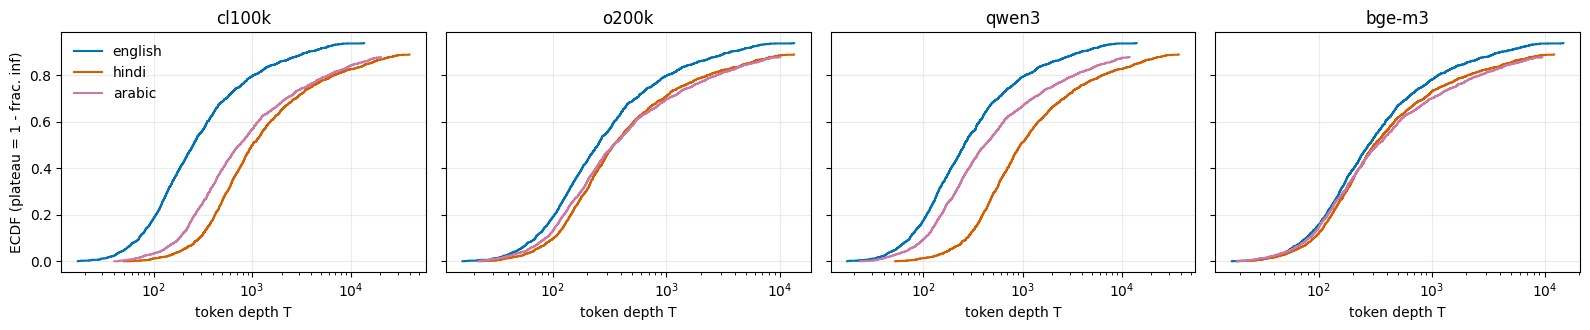

,lang,tokenizer,pct_inf,median_T
0,english,cl100k,6.1,252.0
1,hindi,cl100k,11.1,1006.0
2,arabic,cl100k,12.1,739.0
3,english,o200k,6.1,249.0
4,hindi,o200k,11.1,343.0
5,arabic,o200k,12.1,345.0
6,english,qwen3,6.1,258.0
7,hindi,qwen3,11.1,951.0
8,arabic,qwen3,12.1,417.0
9,english,bge-m3,6.1,275.0


In [87]:
COL = {"english": "#0072B2", "hindi": "#D55E00", "russian": "#009E73", "arabic": "#CC79A7"}
fig, axs = plt.subplots(1, 4, figsize=(16, 3.4), sharey=True)
drows = []
for ax, t in zip(axs, TOKS):
    for l in LANGS:
        T = E["T"][l][t]; x = np.sort(T[np.isfinite(T)])
        ax.step(x, np.arange(1, len(x) + 1) / len(T), where="post", color=COL.get(l, "grey"), label=l)
        drows.append({"lang": l, "tokenizer": t, "pct_inf": 100 * np.mean(~np.isfinite(T)), "median_T": np.median(T)})
    ax.set_xscale("log"); ax.set_title(t); ax.set_xlabel("token depth T"); ax.grid(alpha=.25)
axs[0].set_ylabel("ECDF (plateau = 1 - frac. inf)"); axs[0].legend(frameon=False)
plt.tight_layout(); plt.savefig(OUT / "depth_ecdf.png", dpi=150); plt.show()
DEPTH = pd.DataFrame(drows).round(1); display(DEPTH); DEPTH.to_csv(OUT / "eda_depth.csv", index=False)

### Implementation of the conformal procedure

Core functions, followed by unit tests on synthetic data (including the infeasible case), a feasibility guard, and the repeated-split experiment.

In [88]:
def need_k(n, alpha): return max(1, math.ceil(round((n + 1) * (1 - alpha), 9)))   # round() protects against float error, e.g. 20*0.95

def qh(s_sorted, alpha):               # s_sorted ascending
    n = len(s_sorted); k = need_k(n, alpha)
    return np.inf if k > n else s_sorted[k - 1]      # inf => retrieval-limited or too few items

def qhat(t_cal, alpha): return qh(np.sort(t_cal), alpha)

def cover(T, B):   # B = inf means "use all K_RET": coverage is then capped by recall
    return float(np.mean(np.isfinite(T) & (T <= B)))

def used(C, B):    # tokens actually sent: cumulative cost of the longest prefix within budget
    return float(np.where(C <= B, C, 0).max(1).mean())

def tau_of(s_cal, alpha):              # finite-sample corrected alpha-quantile (lower), for the score-threshold baseline
    k = int(math.floor(round(alpha * (len(s_cal) + 1), 9)))
    return -np.inf if k < 1 else np.sort(s_cal)[k - 1]

def make_splits(groups, R, seed):
    ug, inv = np.unique(groups, return_inverse=True); rng = np.random.default_rng(seed); out = []
    for _ in range(R):
        calg = np.zeros(len(ug), bool); calg[rng.permutation(len(ug))[: len(ug) // 2]] = True
        m = calg[inv]; out.append((np.where(m)[0], np.where(~m)[0]))
    return out

def cn(c, L): return c if L in ("english", "hindi") else f"{c}_{L}"   # Hindi is the primary test language: unsuffixed

In [89]:
# Unit tests on synthetic data
assert qhat(np.arange(1, 10.), 0.1) == 9                         # n=9: k=ceil(10*0.9)=9
assert qhat(np.arange(1, 20.), 0.05) == 19                       # n=19: k=ceil(20*0.95)=19 (float-safe)
assert np.isinf(qhat(np.arange(1, 10.), 0.05))                   # infeasible: k=ceil(9.5)=10 > n=9
assert np.isinf(qhat(np.array([1, 2, 3, np.inf, np.inf]), 0.2))  # retrieval-limited: 5th smallest is inf
assert qhat(np.array([5., 1, 3, 2, 4, 6, 7, 8, 9, 10]), 0.2) == 9   # unsorted input, n=10: k=ceil(8.8)=9
assert cover(np.array([1, 2, np.inf]), 2) == 2 / 3 and cover(np.array([1, 2, np.inf]), np.inf) == 2 / 3
Ct = np.array([[10, 20, 30], [5, 50, 60.]]); assert used(Ct, 25) == 12.5 and used(Ct, 4) == 0.0
assert tau_of(np.array([.1, .2, .3, .4, .5, .6, .7, .8, .9]), 0.2) == .2 and tau_of(np.array([.5, .6]), 0.05) == -np.inf
g_ = np.repeat(np.arange(40), 2); sp = make_splits(g_, 5, 0)
for cal_, te_ in sp:
    assert len(cal_) == len(te_) == 40 and not set(cal_) & set(te_) and not set(g_[cal_]) & set(g_[te_])   # grouped, disjoint, 50/50
assert all((a_[0] == b_[0]).all() and (a_[1] == b_[1]).all() for a_, b_ in zip(sp, make_splits(g_, 5, 0)))   # seeded
rs = np.random.default_rng(1); cv_ = []
for _ in range(2000):                                                # guarantee check on exchangeable data
    x = rs.lognormal(size=61); cv_.append(cover(x[1:], qhat(x[:30], 0.1)))
print("unit tests passed | iid coverage at alpha=0.1, n=30:", round(np.mean(cv_), 3), f"(window [0.900, {0.9 + 1 / 31:.3f}])")
print("infeasible case: qhat(n=9, alpha=0.05) =", qhat(np.arange(1, 10.), 0.05), "| ks_2samp with inf mass ok:",
      round(ks_2samp(np.array([1, 2, 1e18]), np.array([2, 3, 4.])).statistic, 3))

unit tests passed | iid coverage at alpha=0.1, n=30: 0.918 (window [0.900, 0.932])
infeasible case: qhat(n=9, alpha=0.05) = inf | ks_2samp with inf mass ok: 0.333


In [90]:
# Feasibility guard: calibration items per split and (n+1)(1-alpha) > n
SPL0 = make_splits(E["groups"], R, SEED); ncal = np.array([len(c) for c, _ in SPL0])
print(f"calibration items per split: min {ncal.min()} | median {int(np.median(ncal))} | max {ncal.max()}; test items per split: median {int(np.median([len(t) for _, t in SPL0]))}")
for a in ALPHAS:
    if need_k(ncal.min(), a) > ncal.min(): print(f"WARNING: alpha={a}: ceil((n+1)(1-alpha)) = {need_k(ncal.min(), a)} > n = {ncal.min()}: infeasible (B = inf) in some splits")
    for l in LANGS:
        sh = np.mean(~np.isfinite(E["T"][l][TOKS[0]]))
        if sh > a: print(f"WARNING: alpha={a}: {100*sh:.1f}% of {l} items have T = inf (> alpha): budgets are retrieval-limited (B = inf)")
for k in KS_FEW:
    if k > ncal.min(): print(f"note: few-label k={k} exceeds the smallest calibration half ({ncal.min()}); skipped in splits where k > n_cal")
    for a in ALPHAS:
        if k <= ncal.min() and need_k(k, a) > k: print(f"note: few-label k={k}, alpha={a}: ceil((k+1)(1-alpha)) = {need_k(k, a)} > k -> B = inf by construction")

calibration items per split: min 981 | median 1009 | max 1040; test items per split: median 1008
note: few-label k=10, alpha=0.05: ceil((k+1)(1-alpha)) = 11 > k -> B = inf by construction


In [91]:
def run_splits(E, SPL, seed):
    REC, RATIO, BASE = {}, {}, {}
    def rec(cond, t, a, k, cov, B, u=np.nan):
        d = REC.setdefault((cond, t, a, k), {"cov": [], "B": [], "used": []}); d["cov"].append(cov); d["B"].append(B); d["used"].append(u)
    T, C, CO = E["T"], E["C"], E["cost"]; fh = E["first"]["hindi"]
    terc = {t: pd.qcut(pd.Series(E["qtokc"]["english"][t].values).rank(method="first"), 3, labels=False).values for t in TOKS}
    for r, (cal, te) in enumerate(SPL):
        rf = np.random.default_rng(seed + 1000 + r)
        for t in TOKS:
            Te, Th = T["english"][t], T["hindi"][t]
            for a in ALPHAS:
                Ben = qhat(Te[cal], a)
                rec("a", t, a, 0, cover(Te[te], Ben), Ben, used(C["english"][t][te], Ben))
                for L in TEST_LANGS:
                    TL, CL = T[L][t], C[L][t]; BL = qhat(TL[cal], a); Bd = Ben * E["kappa_by"][L][t]
                    rec(cn("b", L), t, a, 0, cover(TL[te], Ben), Ben, used(CL[te], Ben))
                    rec(cn("c", L), t, a, 0, cover(TL[te], BL), BL, used(CL[te], BL))
                    rec(cn("d", L), t, a, 0, cover(TL[te], Bd), Bd, used(CL[te], Bd))
                    if np.isfinite(Ben) and np.isfinite(BL): RATIO.setdefault((t, a, L), []).append(BL / Ben)
                    for tag, src in (("s_c", L), ("s_b", "english")):        # score-threshold baseline: B column holds tau (inf = keep all)
                        tau = tau_of(E["srel"][src][cal], a); keep = E["sc"][L][te] >= tau
                        rec(cn(tag, L), t, a, 0, float((E["hit"][L][te] & keep).any(1).mean()), np.inf if tau == -np.inf else float(tau),
                            float((keep * CO[L][t][te]).sum(1).mean()))
                Bf = qhat(np.concatenate([Te[cal], Th[cal]]), a)
                rec("f", t, a, 0, cover(Th[te], Bf), Bf, used(C["hindi"][t][te], Bf))
                for q in range(3):                                                  # descriptive: (b) by English query-length tercile
                    idx = te[terc[t][te] == q]
                    if len(idx): rec(f"b_terc{q}", t, a, 0, cover(Th[idx], Ben), Ben)
                for k in KS_FEW:
                    if k > len(cal): continue
                    sub = rf.choice(cal, k, replace=False); Bk = qhat(Th[sub], a)
                    rec("e", t, a, k, cover(Th[te], Bk), Bk)
            # baselines (Hindi test); conformal budget matched on *calibration* coverage
            Ch, Cth = C["hindi"][t], CO["hindi"][t]
            for k in TOPK_BASE:
                hitk = (fh >= 0) & (fh < k); Bm = qhat(Th[cal], 1 - hitk[cal].mean())
                BASE.setdefault(("topk", t, k), []).append((hitk[te].mean(), Ch[te, k - 1].mean(), cover(Th[te], Bm), used(Ch[te], Bm)))
            for F_ in FIXED_BUDGETS:
                Bm = qhat(Th[cal], 1 - cover(Th[cal], F_))
                BASE.setdefault(("fixedtok", t, F_), []).append((cover(Th[te], F_), used(Ch[te], F_), cover(Th[te], Bm), used(Ch[te], Bm)))
    return REC, RATIO, BASE

def lang_of(cond):
    for l in TEST_LANGS:
        if cond.endswith("_" + l): return l
    return "english" if cond == "a" else "hindi"

def base_cond(cond):
    for l in TEST_LANGS:
        if cond.endswith("_" + l): return cond[: -len(l) - 1]
    return cond

def summarize(E, REC, RATIO, BASE, seed):
    rows = []
    for (cond, t, a, k), v in REC.items():
        L, bc = lang_of(cond), base_cond(cond); cv, B = np.array(v["cov"]), np.array(v["B"]); fin = B[np.isfinite(B)]
        rows.append(dict(seed=seed, condition=cond, lang=L, tokenizer=t, alpha=a, k=k, n_splits=len(cv), cov_mean=cv.mean(), cov_p5=np.percentile(cv, 5),
                         cov_p95=np.percentile(cv, 95), gap=(1 - a) - cv.mean(), B_median=np.median(fin) if len(fin) else np.nan,
                         B_unit="cosine tau" if bc.startswith("s_") else "tokens", pct_inf=100 * np.mean(~np.isfinite(B)),
                         tokens_used=np.nanmean(v["used"]) if not np.all(np.isnan(v["used"])) else np.nan,
                         kappa=1.0 if L == "english" else E["kappa_by"][L][t],
                         ratio_Bhi_Ben=np.median(RATIO[(t, a, L)]) if bc == "c" and (t, a, L) in RATIO else np.nan,
                         infeasible=int(bc == "e" and need_k(k, a) > k)))
    for (kind, t, p), v in BASE.items():
        v = np.array(v)
        rows.append(dict(seed=seed, condition="base_" + kind, lang="hindi", tokenizer=t, k=p, n_splits=len(v), cov_mean=v[:, 0].mean(), cov_p5=np.percentile(v[:, 0], 5),
                         cov_p95=np.percentile(v[:, 0], 95), tokens_used=v[:, 1].mean(), cov_matched_conformal=v[:, 2].mean(), tokens_matched_conformal=v[:, 3].mean()))
    df = pd.DataFrame(rows); df["k"] = df["k"].astype("Int64")
    return df

In [92]:
# Bootstrap (paired group bootstrap over first-relevant-pid groups), shift statistics, window check, gate
def _members(groups):
    ug, inv = np.unique(groups, return_inverse=True)
    order = np.argsort(inv, kind="stable"); cuts = np.cumsum(np.bincount(inv))[:-1]
    return ug, inv, np.split(order, cuts)

def bootstrap(E, seed):
    ug, inv, members = _members(E["groups"]); rng = np.random.default_rng(seed + 7)
    keys = [(t, a, L) for t in TOKS for a in ALPHAS for L in TEST_LANGS]; acc = {k: {"gap_b": [], "gap_d": [], "ratio": []} for k in keys}
    for _ in range(N_BOOT):
        gs = rng.integers(0, len(ug), len(ug)); idx = np.concatenate([members[g] for g in gs]); lab = inv[idx]; ul = np.unique(gs)
        if len(ul) < 2: continue
        vals = {k: [] for k in keys}
        for _s in range(SPLITS_PER_BOOT):
            m = np.isin(lab, rng.permutation(ul)[: len(ul) // 2]); cal, te = idx[m], idx[~m]
            for t in TOKS:
                se = np.sort(E["T"]["english"][t][cal])
                for L in TEST_LANGS:
                    TL = E["T"][L][t]; sl = np.sort(TL[cal]); kap = E["kappa_by"][L][t]
                    for a in ALPHAS:
                        Ben, BL = qh(se, a), qh(sl, a)
                        vals[(t, a, L)].append(((1 - a) - cover(TL[te], Ben), (1 - a) - cover(TL[te], Ben * kap),
                                                BL / Ben if np.isfinite(Ben) and np.isfinite(BL) else np.nan))
        for k, v in vals.items():
            v = np.array(v); acc[k]["gap_b"].append(v[:, 0].mean()); acc[k]["gap_d"].append(v[:, 1].mean())
            acc[k]["ratio"].append(np.nanmean(v[:, 2]) if np.isfinite(v[:, 2]).any() else np.nan)
    return acc

def _ci(x): x = np.array(x, float); x = x[np.isfinite(x)]; return (np.percentile(x, 2.5), np.percentile(x, 97.5)) if len(x) else (np.nan, np.nan)

def shift_stats(E):
    rows = []
    for L in TEST_LANGS:
        for t in TOKS:
            x, y = E["T"]["english"][t], E["T"][L][t]; fx, fy = x[np.isfinite(x)], y[np.isfinite(y)]
            big = lambda z: np.where(np.isfinite(z), z, 1e18)
            ks_all = ks_2samp(big(x), big(y)).statistic            # includes the T = inf mass: this one bounds the coverage gap
            ks_fin = ks_2samp(fx, fy).statistic if len(fx) and len(fy) else np.nan
            edges = np.unique(np.quantile(np.concatenate([fx, fy]), np.linspace(0, 1, 51)))
            hx, hy = np.histogram(fx, edges)[0], np.histogram(fy, edges)[0]
            tv_fin = 0.5 * np.abs(hx / max(len(fx), 1) - hy / max(len(fy), 1)).sum()
            tv_all = 0.5 * np.abs(np.append(hx, (~np.isfinite(x)).sum()) / len(x) - np.append(hy, (~np.isfinite(y)).sum()) / len(y)).sum()
            rows.append(dict(condition="shift_stats", lang=L, tokenizer=t, ks_all=ks_all, ks_finite=ks_fin, tv_finite=tv_fin, tv_all=tv_all))
    return pd.DataFrame(rows)

def attach_extras(E, RES, BOOT, SPL):
    RES = RES.copy(); n = float(np.mean([len(c) for c, _ in SPL]))
    for c in ("gap_ci_lo", "gap_ci_hi", "ratio_ci_lo", "ratio_ci_hi", "win_lo", "win_hi", "in_window"): RES[c] = np.nan
    for i, r in RES.iterrows():
        if not isinstance(r.alpha, float) or np.isnan(r.alpha): continue
        bc, L = base_cond(r.condition), r.lang
        if bc in ("b", "d") and (r.tokenizer, r.alpha, L) in BOOT:
            RES.loc[i, ["gap_ci_lo", "gap_ci_hi"]] = _ci(BOOT[(r.tokenizer, r.alpha, L)]["gap_b" if bc == "b" else "gap_d"])
        if bc == "c" and (r.tokenizer, r.alpha, L) in BOOT: RES.loc[i, ["ratio_ci_lo", "ratio_ci_hi"]] = _ci(BOOT[(r.tokenizer, r.alpha, L)]["ratio"])
        if bc in ("a", "c"):
            lo, hi = 1 - r.alpha, 1 - r.alpha + 1 / (n + 1); RES.loc[i, ["win_lo", "win_hi"]] = (lo, hi); RES.loc[i, "in_window"] = float(lo <= r.cov_mean <= hi)
    return pd.concat([RES, shift_stats(E)], ignore_index=True)

def gate_from(RES, BOOT, alpha=GATE_ALPHA):
    g = RES[(RES.alpha == alpha) & (RES.lang == "hindi") & RES.condition.isin(["b", "d"])].pivot(index="tokenizer", columns="condition", values="gap").loc[list(TOKS)]
    out = pd.DataFrame({"gap_b": g["b"], "ci_lo": [_ci(BOOT[(t, alpha, "hindi")]["gap_b"])[0] for t in TOKS], "ci_hi": [_ci(BOOT[(t, alpha, "hindi")]["gap_b"])[1] for t in TOKS],
                        "gap_d": g["d"], "gap_d_lo": [_ci(BOOT[(t, alpha, "hindi")]["gap_d"])[0] for t in TOKS], "gap_d_hi": [_ci(BOOT[(t, alpha, "hindi")]["gap_d"])[1] for t in TOKS]})
    out["b_sig"] = (out.gap_b >= GAP_MIN) & (out.ci_lo > 0)
    out["d_closes"] = (out.gap_b >= GAP_MIN) & (out.gap_d.abs() <= NEAR)
    if out.b_sig.sum() >= 2: v = "PROCEED"
    elif out.d_closes.sum() >= 2: v = "PROCEED (method)"
    elif (out.gap_b.abs() <= NEAR).all(): v = "PIVOT"
    else: v = "CAUTION"
    return out, v

def analyze(E, seed):
    SPL = make_splits(E["groups"], R, seed)
    REC, RATIO, BASE = run_splits(E, SPL, seed); RES = summarize(E, REC, RATIO, BASE, seed)
    BOOT = bootstrap(E, seed); RES = attach_extras(E, RES, BOOT, SPL); GATE, V = gate_from(RES, BOOT)
    return dict(SPL=SPL, REC=REC, RATIO=RATIO, BASE=BASE, RES=RES, BOOT=BOOT, GATE=GATE, VERDICT=V)

In [93]:
A = analyze(E, SEED)                       # pre-committed analysis (SEED)
REC, RATIO, BASE, RES, BOOT, GATE, VERDICT = A["REC"], A["RATIO"], A["BASE"], A["RES"], A["BOOT"], A["GATE"], A["VERDICT"]
RES.to_csv(OUT / "results.csv", index=False)
print(f"{len(A['SPL'])} splits; {len(RES)} result rows -> {OUT.name}/results.csv")

200 splits; 280 result rows -> outputs/results.csv


## 5. Results

Tables are reported per $\alpha$ (target coverage $1-\alpha$). For each condition the table gives the mean test coverage over the splits and its 5th–95th percentile, the gap $(1-\alpha)-$coverage, the median budget $B$ (finite splits only; "n/a" if every split is infinite), the share of splits with $B=\infty$, the mean number of tokens sent, and $\kappa$. Condition codes: a EN→EN, b EN→HI, c HI→HI, d EN×κ→HI, e few-label HI, f pooled→HI, s_c / s_b score-threshold baseline calibrated on Hindi / English (its $B$ column is the cosine threshold $\tau$).

**Note (MLQA).** Coverage here means *evidence* coverage: the budget reaches a passage that contains the gold answer string (`REL_MODE`). The pool-comparison table of Robustness 2 is kept only so the cell runs; it is **not meaningful** here (there is no BM25-only pool, so it has one row). If more than a fraction $\alpha$ of questions have no evidence in the top $K_{\mathrm{RET}}$, the unconditional budgets at that $\alpha$ are retrieval-limited ($B=\infty$) and the conditional-coverage cell (EXTRA 2) is the primary analysis.

In [94]:
def show(df): display(df.round(3).astype(object).where(df.notna(), "n/a").reset_index(drop=True))
cols = ["condition", "lang", "tokenizer", "alpha", "k", "cov_mean", "cov_p5", "cov_p95", "gap", "gap_ci_lo", "gap_ci_hi", "B_median", "ratio_Bhi_Ben", "ratio_ci_lo", "ratio_ci_hi", "kappa", "pct_inf", "tokens_used"]
MAIN = ["a", "b", "c", "d", "f", "s_c", "s_b"]
for a in ALPHAS:
    print(f"\n=== alpha = {a} (target coverage {1-a:.2f}) ===")
    show(RES[(RES.alpha == a) & RES.condition.map(base_cond).isin(MAIN)][cols].sort_values(["lang", "tokenizer", "condition"]))
print("\n=== (e) few-label Hindi calibration ==="); show(RES[RES.condition == "e"][cols + ["infeasible"]].sort_values(["alpha", "tokenizer", "k"]))
print("\n=== baselines (Hindi test; conformal budget matched on calibration coverage) ===")
show(RES[RES.condition.fillna("").str.startswith("base_")].dropna(axis=1, how="all").sort_values(["tokenizer", "condition", "k"]))


=== alpha = 0.05 (target coverage 0.95) ===


,condition,lang,tokenizer,alpha,k,cov_mean,cov_p5,cov_p95,gap,gap_ci_lo,gap_ci_hi,B_median,ratio_Bhi_Ben,ratio_ci_lo,ratio_ci_hi,kappa,pct_inf,tokens_used
0,b_arabic,arabic,bge-m3,0.05,0,0.878,0.866,0.889,0.072,0.057,0.087,11387.5,n/a,n/a,n/a,1.173,99.0,7915.871
1,c_arabic,arabic,bge-m3,0.05,0,0.878,0.866,0.889,0.072,n/a,n/a,n/a,n/a,n/a,n/a,1.173,100.0,7917.584
2,d_arabic,arabic,bge-m3,0.05,0,0.878,0.866,0.889,0.072,0.057,0.087,13358.149,n/a,n/a,n/a,1.173,99.0,7917.243
3,s_b_arabic,arabic,bge-m3,0.05,0,0.856,0.839,0.871,0.094,n/a,n/a,0.376,n/a,n/a,n/a,1.173,0.0,5974.015
4,s_c_arabic,arabic,bge-m3,0.05,0,0.877,0.864,0.888,0.073,n/a,n/a,0.333,n/a,n/a,n/a,1.173,0.0,7608.746
5,b_arabic,arabic,cl100k,0.05,0,0.878,0.866,0.889,0.072,0.061,0.097,10553.5,n/a,n/a,n/a,3.027,99.0,17454.341
6,c_arabic,arabic,cl100k,0.05,0,0.878,0.866,0.889,0.072,n/a,n/a,n/a,n/a,n/a,n/a,3.027,100.0,17527.462
7,d_arabic,arabic,cl100k,0.05,0,0.878,0.866,0.889,0.072,0.057,0.087,31948.584,n/a,n/a,n/a,3.027,99.0,17527.157
8,s_b_arabic,arabic,cl100k,0.05,0,0.856,0.839,0.871,0.094,n/a,n/a,0.376,n/a,n/a,n/a,3.027,0.0,13254.205
9,s_c_arabic,arabic,cl100k,0.05,0,0.877,0.864,0.888,0.073,n/a,n/a,0.333,n/a,n/a,n/a,3.027,0.0,16850.44



=== alpha = 0.1 (target coverage 0.90) ===


,condition,lang,tokenizer,alpha,k,cov_mean,cov_p5,cov_p95,gap,gap_ci_lo,gap_ci_hi,B_median,ratio_Bhi_Ben,ratio_ci_lo,ratio_ci_hi,kappa,pct_inf,tokens_used
0,b_arabic,arabic,bge-m3,0.1,0,0.836,0.809,0.86,0.064,0.046,0.086,4162.0,n/a,n/a,n/a,1.173,0.0,4082.986
1,c_arabic,arabic,bge-m3,0.1,0,0.878,0.866,0.889,0.022,n/a,n/a,9554.0,2.624,1.559,3.493,1.173,99.5,7916.566
2,d_arabic,arabic,bge-m3,0.1,0,0.847,0.821,0.867,0.053,0.036,0.075,4882.25,n/a,n/a,n/a,1.173,0.0,4812.114
3,s_b_arabic,arabic,bge-m3,0.1,0,0.791,0.758,0.819,0.109,n/a,n/a,0.425,n/a,n/a,n/a,1.173,0.0,3327.42
4,s_c_arabic,arabic,bge-m3,0.1,0,0.859,0.841,0.874,0.041,n/a,n/a,0.374,n/a,n/a,n/a,1.173,0.0,6154.132
5,b_arabic,arabic,cl100k,0.1,0,0.76,0.73,0.792,0.14,0.115,0.166,3743.0,n/a,n/a,n/a,3.027,0.0,3415.803
6,c_arabic,arabic,cl100k,0.1,0,0.878,0.866,0.889,0.022,n/a,n/a,20228.0,6.197,3.835,8.039,3.027,99.5,17524.346
7,d_arabic,arabic,cl100k,0.1,0,0.85,0.827,0.87,0.05,0.033,0.072,11331.174,n/a,n/a,n/a,3.027,0.0,11202.397
8,s_b_arabic,arabic,cl100k,0.1,0,0.791,0.758,0.819,0.109,n/a,n/a,0.425,n/a,n/a,n/a,3.027,0.0,7388.132
9,s_c_arabic,arabic,cl100k,0.1,0,0.859,0.841,0.874,0.041,n/a,n/a,0.374,n/a,n/a,n/a,3.027,0.0,13651.519



=== alpha = 0.2 (target coverage 0.80) ===


,condition,lang,tokenizer,alpha,k,cov_mean,cov_p5,cov_p95,gap,gap_ci_lo,gap_ci_hi,B_median,ratio_Bhi_Ben,ratio_ci_lo,ratio_ci_hi,kappa,pct_inf,tokens_used
0,b_arabic,arabic,bge-m3,0.2,0,0.719,0.69,0.748,0.081,0.059,0.106,1158.5,n/a,n/a,n/a,1.173,0.0,978.236
1,c_arabic,arabic,bge-m3,0.2,0,0.801,0.768,0.831,-0.001,n/a,n/a,2694.5,2.286,1.88,2.897,1.173,0.0,2476.344
2,d_arabic,arabic,bge-m3,0.2,0,0.737,0.71,0.761,0.063,0.043,0.087,1358.983,n/a,n/a,n/a,1.173,0.0,1182.787
3,s_b_arabic,arabic,bge-m3,0.2,0,0.65,0.618,0.682,0.15,n/a,n/a,0.477,n/a,n/a,n/a,1.173,0.0,1318.511
4,s_c_arabic,arabic,bge-m3,0.2,0,0.788,0.759,0.816,0.012,n/a,n/a,0.426,n/a,n/a,n/a,1.173,0.0,3255.615
5,b_arabic,arabic,cl100k,0.2,0,0.584,0.538,0.63,0.216,0.179,0.262,1068.0,n/a,n/a,n/a,3.027,0.0,673.144
6,c_arabic,arabic,cl100k,0.2,0,0.801,0.769,0.832,-0.001,n/a,n/a,6026.0,5.612,4.572,7.05,3.027,0.0,5517.114
7,d_arabic,arabic,cl100k,0.2,0,0.744,0.719,0.768,0.056,0.037,0.081,3233.154,n/a,n/a,n/a,3.027,0.0,2800.832
8,s_b_arabic,arabic,cl100k,0.2,0,0.65,0.618,0.682,0.15,n/a,n/a,0.477,n/a,n/a,n/a,3.027,0.0,2926.434
9,s_c_arabic,arabic,cl100k,0.2,0,0.788,0.759,0.816,0.012,n/a,n/a,0.426,n/a,n/a,n/a,3.027,0.0,7228.536



=== (e) few-label Hindi calibration ===


,condition,lang,tokenizer,alpha,k,cov_mean,cov_p5,cov_p95,gap,gap_ci_lo,gap_ci_hi,B_median,ratio_Bhi_Ben,ratio_ci_lo,ratio_ci_hi,kappa,pct_inf,tokens_used,infeasible
0,e,hindi,bge-m3,0.05,10,0.89,0.879,0.904,0.06,n/a,n/a,n/a,n/a,n/a,n/a,1.247,100.0,n/a,1.0
1,e,hindi,bge-m3,0.05,25,0.889,0.876,0.904,0.061,n/a,n/a,6281.0,n/a,n/a,n/a,1.247,95.0,n/a,0.0
2,e,hindi,bge-m3,0.05,50,0.89,0.878,0.904,0.06,n/a,n/a,5491.0,n/a,n/a,n/a,1.247,98.5,n/a,0.0
3,e,hindi,bge-m3,0.05,100,0.89,0.878,0.904,0.06,n/a,n/a,7726.5,n/a,n/a,n/a,1.247,99.0,n/a,0.0
4,e,hindi,bge-m3,0.05,200,0.89,0.879,0.904,0.06,n/a,n/a,n/a,n/a,n/a,n/a,1.247,100.0,n/a,0.0
5,e,hindi,cl100k,0.05,10,0.89,0.879,0.904,0.06,n/a,n/a,n/a,n/a,n/a,n/a,4.759,100.0,n/a,1.0
6,e,hindi,cl100k,0.05,25,0.889,0.875,0.904,0.061,n/a,n/a,21999.0,n/a,n/a,n/a,4.759,95.5,n/a,0.0
7,e,hindi,cl100k,0.05,50,0.89,0.879,0.904,0.06,n/a,n/a,n/a,n/a,n/a,n/a,4.759,100.0,n/a,0.0
8,e,hindi,cl100k,0.05,100,0.89,0.879,0.904,0.06,n/a,n/a,n/a,n/a,n/a,n/a,4.759,100.0,n/a,0.0
9,e,hindi,cl100k,0.05,200,0.89,0.879,0.904,0.06,n/a,n/a,n/a,n/a,n/a,n/a,4.759,100.0,n/a,0.0



=== baselines (Hindi test; conformal budget matched on calibration coverage) ===


,seed,condition,lang,tokenizer,k,n_splits,cov_mean,cov_p5,cov_p95,tokens_used,cov_matched_conformal,tokens_matched_conformal
0,0.0,base_fixedtok,hindi,bge-m3,256,200.0,0.442,0.422,0.461,113.888,0.444,114.816
1,0.0,base_fixedtok,hindi,bge-m3,512,200.0,0.623,0.603,0.642,335.921,0.625,340.712
2,0.0,base_fixedtok,hindi,bge-m3,1024,200.0,0.736,0.717,0.752,829.358,0.737,842.675
3,0.0,base_fixedtok,hindi,bge-m3,2048,200.0,0.799,0.784,0.815,1829.003,0.801,1840.418
4,0.0,base_topk,hindi,bge-m3,1,200.0,0.586,0.568,0.603,244.752,0.587,267.808
5,0.0,base_topk,hindi,bge-m3,3,200.0,0.734,0.718,0.751,807.357,0.736,842.637
6,0.0,base_topk,hindi,bge-m3,5,200.0,0.781,0.765,0.797,1381.714,0.781,1441.762
7,0.0,base_topk,hindi,bge-m3,10,200.0,0.829,0.815,0.844,2835.144,0.829,2998.858
8,0.0,base_fixedtok,hindi,cl100k,256,200.0,0.079,0.069,0.088,20.168,0.08,20.756
9,0.0,base_fixedtok,hindi,cl100k,512,200.0,0.273,0.253,0.29,136.546,0.274,137.618


In [95]:
print("=== within-language validity: mean coverage vs window [1-alpha, 1-alpha+1/(n_cal+1)] (n_cal = mean calibration size) ===")
V_ = RES[RES.condition.map(base_cond).isin(["a", "c"]) & (RES.lang.isin(["english", "hindi"]))][["condition", "tokenizer", "alpha", "cov_mean", "win_lo", "win_hi", "in_window", "pct_inf"]]
show(V_.sort_values(["condition", "alpha", "tokenizer"])); V_.to_csv(OUT / "validity_window.csv", index=False)
print("\n=== EN vs target-language depth distributions (finite = finite depths only; all = includes T=inf mass, bounds the coverage gap) ===")
show(RES[RES.condition == "shift_stats"][["lang", "tokenizer", "ks_all", "ks_finite", "tv_finite", "tv_all"]])
print("\n=== (b) coverage by English query-length tercile (descriptive; Hindi test, alpha=0.1) ===")
tb = RES[(RES.alpha == GATE_ALPHA) & RES.condition.str.startswith("b_terc")].pivot(index="tokenizer", columns="condition", values="cov_mean"); show(tb.reset_index())
print("\n=== share of splits with B = inf, by condition (alpha, tokenizer) ===")
Z = RES[RES.alpha.notna()].assign(cond=lambda d: d.condition + np.where(d.condition == "e", "_k" + d.k.astype(str), ""))
for a in ALPHAS: print(f"alpha={a}"); display(Z[Z.alpha == a].pivot_table(index="cond", columns="tokenizer", values="pct_inf").round(1).reindex(columns=list(TOKS)))

=== within-language validity: mean coverage vs window [1-alpha, 1-alpha+1/(n_cal+1)] (n_cal = mean calibration size) ===


,condition,tokenizer,alpha,cov_mean,win_lo,win_hi,in_window,pct_inf
0,a,bge-m3,0.05,0.939,0.95,0.951,0.0,99.0
1,a,cl100k,0.05,0.939,0.95,0.951,0.0,99.0
2,a,o200k,0.05,0.939,0.95,0.951,0.0,99.0
3,a,qwen3,0.05,0.939,0.95,0.951,0.0,99.0
4,a,bge-m3,0.1,0.902,0.9,0.901,0.0,0.0
5,a,cl100k,0.1,0.902,0.9,0.901,0.0,0.0
6,a,o200k,0.1,0.902,0.9,0.901,0.0,0.0
7,a,qwen3,0.1,0.902,0.9,0.901,0.0,0.0
8,a,bge-m3,0.2,0.804,0.8,0.801,0.0,0.0
9,a,cl100k,0.2,0.804,0.8,0.801,0.0,0.0



=== EN vs target-language depth distributions (finite = finite depths only; all = includes T=inf mass, bounds the coverage gap) ===


,lang,tokenizer,ks_all,ks_finite,tv_finite,tv_all
0,hindi,cl100k,0.458,0.48,0.482,0.459
1,hindi,o200k,0.126,0.119,0.154,0.166
2,hindi,qwen3,0.432,0.451,0.453,0.432
3,hindi,bge-m3,0.061,0.039,0.094,0.112
4,arabic,cl100k,0.32,0.327,0.341,0.333
5,arabic,o200k,0.117,0.084,0.132,0.152
6,arabic,qwen3,0.148,0.126,0.172,0.189
7,arabic,bge-m3,0.088,0.041,0.092,0.116



=== (b) coverage by English query-length tercile (descriptive; Hindi test, alpha=0.1) ===


condition,tokenizer,b_terc0,b_terc1,b_terc2
0,bge-m3,0.753,0.87,0.913
1,cl100k,0.637,0.771,0.831
2,o200k,0.745,0.851,0.9
3,qwen3,0.651,0.785,0.836


... (2 outputs left out)

alpha=0.1


tokenizer,cl100k,o200k,qwen3,bge-m3
cond,,,,
a,0.0,0.0,0.0,0.0
b,0.0,0.0,0.0,0.0
b_arabic,0.0,0.0,0.0,0.0
b_terc0,0.0,0.0,0.0,0.0
b_terc1,0.0,0.0,0.0,0.0
b_terc2,0.0,0.0,0.0,0.0
c,96.0,96.0,96.0,96.0
c_arabic,99.5,99.5,99.5,99.5
d,0.0,0.0,0.0,0.0


alpha=0.2


tokenizer,cl100k,o200k,qwen3,bge-m3
cond,,,,
a,0.0,0.0,0.0,0.0
b,0.0,0.0,0.0,0.0
b_arabic,0.0,0.0,0.0,0.0
b_terc0,0.0,0.0,0.0,0.0
b_terc1,0.0,0.0,0.0,0.0
b_terc2,0.0,0.0,0.0,0.0
c,0.0,0.0,0.0,0.0
c_arabic,0.0,0.0,0.0,0.0
d,0.0,0.0,0.0,0.0


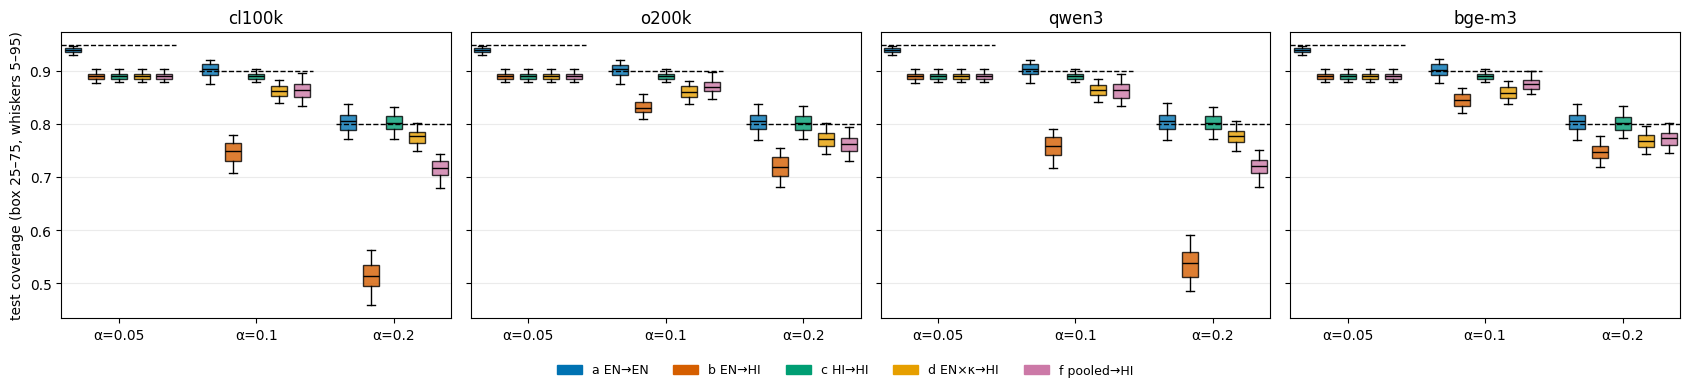

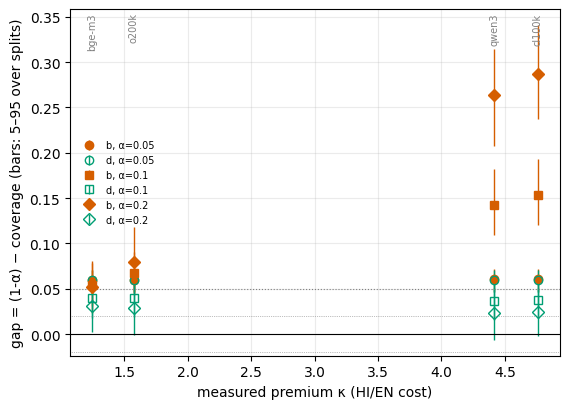

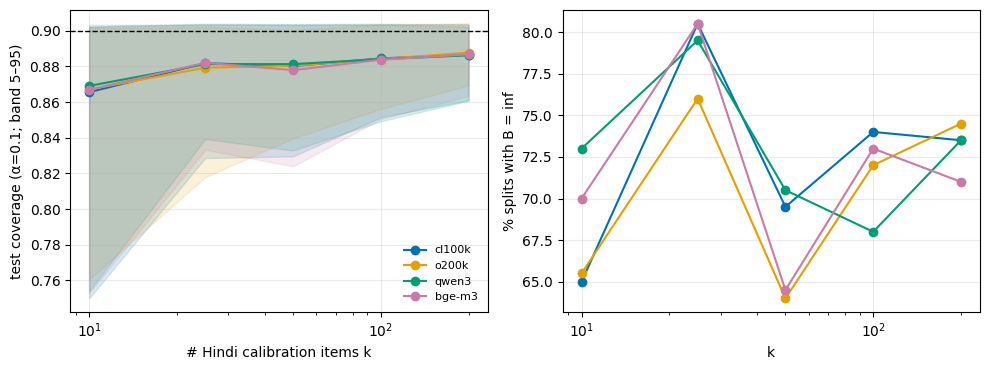

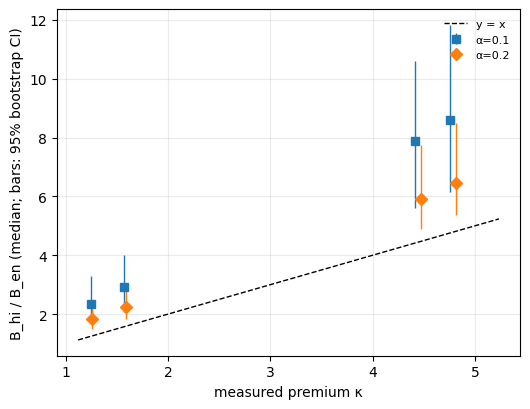

In [96]:
CONDS = [("a", "a EN→EN", "#0072B2"), ("b", "b EN→HI", "#D55E00"), ("c", "c HI→HI", "#009E73"), ("d", "d EN×κ→HI", "#E69F00"), ("f", "f pooled→HI", "#CC79A7")]
TC = dict(zip(TOKS, ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]))

fig, axs = plt.subplots(1, 4, figsize=(17, 3.9), sharey=True)
for ax, t in zip(axs, TOKS):
    for ai, a in enumerate(ALPHAS):
        for ci, (c, lab, col) in enumerate(CONDS):
            bp = ax.boxplot(REC[(c, t, a, 0)]["cov"], positions=[ai * 6 + ci], widths=.7, patch_artist=True, showfliers=False, whis=(5, 95))
            for b in bp["boxes"]: b.set(facecolor=col, alpha=.8)
            for m in bp["medians"]: m.set(color="k")
        ax.hlines(1 - a, ai * 6 - .5, ai * 6 + 4.5, color="k", ls="--", lw=1)
    ax.set_xticks([ai * 6 + 2 for ai in range(3)]); ax.set_xticklabels([f"α={a}" for a in ALPHAS]); ax.set_title(t); ax.grid(axis="y", alpha=.25)
axs[0].set_ylabel("test coverage (box 25–75, whiskers 5–95)")
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for _, _, c in CONDS], labels=[l for _, l, _ in CONDS], frameon=False, fontsize=9, loc="lower center", ncol=5)
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.savefig(OUT / "coverage_vs_alpha.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(5.8, 4.2))
for a, mk in zip(ALPHAS, "osD"):
    for c, col, fill in (("b", "#D55E00", True), ("d", "#009E73", False)):
        s = RES[(RES.condition == c) & (RES.alpha == a)].set_index("tokenizer").loc[list(TOKS)]
        g_ = {t: (1 - a) - np.array(REC[(c, t, a, 0)]["cov"]) for t in TOKS}
        lo = [s.gap[t] - np.percentile(g_[t], 5) for t in TOKS]; hi = [np.percentile(g_[t], 95) - s.gap[t] for t in TOKS]
        ax.errorbar(s.kappa, s.gap, yerr=[lo, hi], fmt=mk, mfc=col if fill else "none", color=col, ms=6, lw=1, label=f"{c}, α={a}")
for t in TOKS: ax.annotate(t, (E["kappa"][t], 0.99), xycoords=("data", "axes fraction"), rotation=90, va="top", ha="center", fontsize=7, color="grey")
ax.axhline(0, color="k", lw=.8); ax.axhline(GAP_MIN, color="grey", ls=":", lw=.8); ax.axhline(-NEAR, color="grey", ls=":", lw=.5); ax.axhline(NEAR, color="grey", ls=":", lw=.5)
ax.set_xlabel("measured premium κ (HI/EN cost)"); ax.set_ylabel("gap = (1-α) − coverage (bars: 5–95 over splits)")
ax.legend(frameon=False, fontsize=7); ax.grid(alpha=.25); plt.tight_layout(); plt.savefig(OUT / "gap_vs_premium.png", dpi=150); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(10, 3.8)); a = GATE_ALPHA
for t in TOKS:
    e = RES[(RES.condition == "e") & (RES.alpha == a) & (RES.tokenizer == t)].sort_values("k")
    if len(e):
        ks_x = e.k.astype(int); axs[0].plot(ks_x, e.cov_mean, "o-", color=TC[t], label=t); axs[0].fill_between(ks_x, e.cov_p5, e.cov_p95, color=TC[t], alpha=.15)
        axs[1].plot(ks_x, e.pct_inf, "o-", color=TC[t], label=t)
axs[0].axhline(1 - a, color="k", ls="--", lw=1); axs[0].set_xscale("log"); axs[0].set_xlabel("# Hindi calibration items k"); axs[0].set_ylabel(f"test coverage (α={a}; band 5–95)")
axs[1].set_xscale("log"); axs[1].set_xlabel("k"); axs[1].set_ylabel("% splits with B = inf")
for ax in axs: ax.grid(alpha=.25)
axs[0].legend(frameon=False, fontsize=8); plt.tight_layout(); plt.savefig(OUT / "label_efficiency.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(5.4, 4.2)); xs = [E["kappa"][t] for t in TOKS]; lim = [0.9 * min(xs), 1.1 * max(xs)]
ax.plot(lim, lim, "k--", lw=1, label="y = x")
for j, (a, mk) in enumerate(zip(ALPHAS, "osD")):
    s = RES[(RES.condition == "c") & (RES.alpha == a) & (RES.lang == "hindi")].set_index("tokenizer").loc[list(TOKS)]
    if s.ratio_Bhi_Ben.notna().any():
        ax.errorbar(s.kappa * (1 + 0.012 * (j - 1)), s.ratio_Bhi_Ben, yerr=[(s.ratio_Bhi_Ben - s.ratio_ci_lo).clip(lower=0), (s.ratio_ci_hi - s.ratio_Bhi_Ben).clip(lower=0)], fmt=mk, ms=6, lw=1, label=f"α={a}")
ax.set_xlabel("measured premium κ"); ax.set_ylabel("B_hi / B_en (median; bars: 95% bootstrap CI)"); ax.legend(frameon=False, fontsize=8); ax.grid(alpha=.25)
plt.tight_layout(); plt.savefig(OUT / "ratio_vs_kappa.png", dpi=150); plt.show()

## 6. Gate verdict and discussion

The gate uses the pre-committed thresholds (`GAP_MIN`, `NEAR`) at $\alpha=0.1$ and the primary seed `SEED`. The bootstrap resamples whole groups (on MLQA a group is an English context) with replacement, keeps English and Hindi items of the same question together, and averages the gap over 10 random 50/50 splits per replicate. Robustness checks follow: the verdict for two other seeds; the pool comparison has a single row on MLQA (the pool is the full corpus, `RUN_NOREL_ROBUSTNESS = False`).

In [97]:
display(GATE.round(4)); GATE.to_csv(OUT / "gate.csv")
print("GATE VERDICT:", VERDICT, f"(gap = (1-alpha) - coverage; GAP_MIN={GAP_MIN}, NEAR={NEAR}; alpha={GATE_ALPHA}; seed={SEED})")
if EXTRA_LANGS:
    print("\n=== extra test languages: conditions b, c, d (alpha=0.1) ===")
    show(RES[(RES.alpha == GATE_ALPHA) & RES.lang.isin(EXTRA_LANGS) & RES.condition.map(base_cond).isin(["b", "c", "d"])][cols].sort_values(["lang", "condition", "tokenizer"]))

,gap_b,ci_lo,ci_hi,gap_d,gap_d_lo,gap_d_hi,b_sig,d_closes
tokenizer,,,,,,,,
cl100k,0.1537,0.1300,0.1883,0.0376,0.0227,0.0582,True,False
o200k,0.0678,0.0502,0.0892,0.0395,0.0244,0.0600,True,False
qwen3,0.1426,0.1199,0.1753,0.0364,0.0217,0.0571,True,False
bge-m3,0.0546,0.0374,0.0752,0.0402,0.0243,0.0611,True,False


GATE VERDICT: PROCEED (gap = (1-alpha) - coverage; GAP_MIN=0.05, NEAR=0.02; alpha=0.1; seed=0)

=== extra test languages: conditions b, c, d (alpha=0.1) ===


,condition,lang,tokenizer,alpha,k,cov_mean,cov_p5,cov_p95,gap,gap_ci_lo,gap_ci_hi,B_median,ratio_Bhi_Ben,ratio_ci_lo,ratio_ci_hi,kappa,pct_inf,tokens_used
0,b_arabic,arabic,bge-m3,0.1,0,0.836,0.809,0.86,0.064,0.046,0.086,4162.0,n/a,n/a,n/a,1.173,0.0,4082.986
1,b_arabic,arabic,cl100k,0.1,0,0.76,0.73,0.792,0.14,0.115,0.166,3743.0,n/a,n/a,n/a,3.027,0.0,3415.803
2,b_arabic,arabic,o200k,0.1,0,0.824,0.8,0.848,0.076,0.055,0.097,3695.0,n/a,n/a,n/a,1.381,0.0,3596.856
3,b_arabic,arabic,qwen3,0.1,0,0.814,0.787,0.837,0.086,0.065,0.109,3928.0,n/a,n/a,n/a,1.629,0.0,3746.409
4,c_arabic,arabic,bge-m3,0.1,0,0.878,0.866,0.889,0.022,n/a,n/a,9554.0,2.624,1.559,3.493,1.173,99.5,7916.566
5,c_arabic,arabic,cl100k,0.1,0,0.878,0.866,0.889,0.022,n/a,n/a,20228.0,6.197,3.835,8.039,3.027,99.5,17524.346
6,c_arabic,arabic,o200k,0.1,0,0.878,0.866,0.889,0.022,n/a,n/a,10104.0,3.135,1.816,3.944,1.381,99.5,8243.342
7,c_arabic,arabic,qwen3,0.1,0,0.878,0.866,0.889,0.022,n/a,n/a,12020.0,3.527,2.108,4.517,1.629,99.5,9917.872
8,d_arabic,arabic,bge-m3,0.1,0,0.847,0.821,0.867,0.053,0.036,0.075,4882.25,n/a,n/a,n/a,1.173,0.0,4812.114
9,d_arabic,arabic,cl100k,0.1,0,0.85,0.827,0.87,0.05,0.033,0.072,11331.174,n/a,n/a,n/a,3.027,0.0,11202.397


In [98]:
# Robustness 1: three seeds (only the SEED verdict is the pre-committed one)
srows, A_SEEDS = [], {SEED: A}
for s in SEEDS:
    if s not in A_SEEDS: A_SEEDS[s] = analyze(E, s)
    g = A_SEEDS[s]["GATE"]
    srows.append({"seed": s, "pre-committed": s == SEED, "verdict": A_SEEDS[s]["VERDICT"], **{f"gap_b[{t}]": round(g.gap_b[t], 4) for t in TOKS},
                  **{f"gap_d[{t}]": round(g.gap_d[t], 4) for t in TOKS}, "n_b_sig": int(g.b_sig.sum()), "n_d_closes": int(g.d_closes.sum())})
SEEDTAB = pd.DataFrame(srows); display(SEEDTAB); SEEDTAB.to_csv(OUT / "gate_seeds.csv", index=False)

,seed,pre-committed,verdict,gap_b[cl100k],gap_b[o200k],gap_b[qwen3],gap_b[bge-m3],gap_d[cl100k],gap_d[o200k],gap_d[qwen3],gap_d[bge-m3],n_b_sig,n_d_closes
0,0,True,PROCEED,0.1537,0.0678,0.1426,0.0546,0.0376,0.0395,0.0364,0.0402,4,0
1,1,False,PROCEED,0.1585,0.0708,0.1469,0.0578,0.0403,0.0421,0.0390,0.0430,4,0
2,2,False,PROCEED,0.1605,0.0716,0.1487,0.0586,0.0412,0.0431,0.0398,0.0438,4,0


In [99]:
# Robustness 2: relevant passages forced into the pool (optimistic) vs BM25 top-100 only
def pool_rows(E_, A_, setting):
    rows = []
    for t in TOKS:
        g = A_["GATE"]; r = {"setting": setting, "tokenizer": t}
        for l in LANGS: r[f"recall@{K_RET}_{l}"] = (E_["first"][l] >= 0).mean(); r[f"pct_inf_{l}"] = 100 * np.mean(~np.isfinite(E_["T"][l][t]))
        r.update(gap_b=g.gap_b[t], ci_lo=g.ci_lo[t], ci_hi=g.ci_hi[t], gap_d=g.gap_d[t], verdict=A_["VERDICT"]); rows.append(r)
    return rows
NAME = {True: "MLQA full corpus (all pairs; only setting, not a comparison)", False: "BM25 top-100 only (n/a on MLQA)"}
prow = pool_rows(E, A, NAME[E["include_rel"]])
if RUN_NOREL_ROBUSTNESS:
    DS_ALT = {**make_ds(not INCLUDE_REL_IN_POOL), "qids": DS["qids"]}      # same queries, other pool setting
    E_ALT = get_E(DS_ALT, "dense"); A_ALT = analyze(E_ALT, SEED); prow += pool_rows(E_ALT, A_ALT, NAME[E_ALT["include_rel"]])
POOLTAB = pd.DataFrame(prow); show(POOLTAB.sort_values(["tokenizer", "setting"])); POOLTAB.to_csv(OUT / "pool_comparison.csv", index=False)

,setting,tokenizer,recall@30_english,pct_inf_english,recall@30_hindi,pct_inf_hindi,recall@30_arabic,pct_inf_arabic,gap_b,ci_lo,ci_hi,gap_d,verdict
0,"MLQA full corpus (all pairs; only setting, not...",bge-m3,0.939,6.148,0.889,11.056,0.879,12.147,0.055,0.037,0.075,0.04,PROCEED
1,"MLQA full corpus (all pairs; only setting, not...",cl100k,0.939,6.148,0.889,11.056,0.879,12.147,0.154,0.13,0.188,0.038,PROCEED
2,"MLQA full corpus (all pairs; only setting, not...",o200k,0.939,6.148,0.889,11.056,0.879,12.147,0.068,0.05,0.089,0.039,PROCEED
3,"MLQA full corpus (all pairs; only setting, not...",qwen3,0.939,6.148,0.889,11.056,0.879,12.147,0.143,0.12,0.175,0.036,PROCEED


In [100]:
# Optional: cross-encoder reranking of the top RERANK_TOP dense candidates (whole pipeline, separate files)
if USE_RERANKER:
    E_RR = get_E(DS, "rerank"); A_RR = analyze(E_RR, SEED)
    A_RR["RES"].to_csv(OUT / "results_reranked.csv", index=False); A_RR["GATE"].to_csv(OUT / "gate_reranked.csv")
    print({l: round(float((E_RR["first"][l] >= 0).mean()), 4) for l in LANGS}, "recall@K reranked | dense:", {l: round(float((E["first"][l] >= 0).mean()), 4) for l in LANGS})
    display(A_RR["GATE"].round(4)); print("GATE VERDICT (reranked):", A_RR["VERDICT"])
else: print("USE_RERANKER = False")

USE_RERANKER = False


In [101]:
def fm(x, f="{:.3f}"): return "n/a" if x is None or (isinstance(x, (float, np.floating)) and not np.isfinite(x)) else f.format(x)
def g1(c, t, a=GATE_ALPHA, L="hindi", col="cov_mean"): return RES[(RES.condition == cn(c, L)) & (RES.tokenizer == t) & (RES.alpha == a) & (RES.lang == L)].iloc[0][col]
r_ = lambda l: (E["first"][l] >= 0).mean()
print("=" * 78); print("SUMMARY")
print(f"1. N={len(E['qids'])} queries ({'QUICK' if QUICK else 'FULL'}, {'GPU' if CUDA else 'CPU'}); pool: {POOL_MODE.split(';')[0]}, include_rel={E['include_rel']}; K_RET={K_RET}; R={R} group splits; seed {SEED}.")
print(f"2. Retrieval: recall@{K_RET} EN {fm(r_('english'))} / HI {fm(r_('hindi'))}; MRR@10 EN {fm(RET.loc['MRR@10','english'])} / HI {fm(RET.loc['MRR@10','hindi'])}; BM25-only pool: " +
      (f"recall EN {fm((E_ALT['first']['english']>=0).mean())} / HI {fm((E_ALT['first']['hindi']>=0).mean())}." if RUN_NOREL_ROBUSTNESS else "not applicable (MLQA pool = full corpus)."))
ks_ = RES[(RES.condition == "shift_stats") & (RES.lang == "hindi")].set_index("tokenizer")
print(f"3. kappa (HI/EN, {E['kappa_source']}): " + ", ".join(f"{t} {E['kappa'][t]:.2f}" for t in TOKS) + "; KS(all) EN vs HI: " + ", ".join(f"{t} {fm(ks_.ks_all[t])}" for t in TOKS) + ".")
print("4. alpha=0.1 coverage (target 0.900) a EN->EN: " + ", ".join(f"{t} {fm(g1('a', t, L='english'))}" for t in TOKS) + " | c HI->HI: " + ", ".join(f"{t} {fm(g1('c', t))}" for t in TOKS) + " | b EN->HI: " + ", ".join(f"{t} {fm(g1('b', t))}" for t in TOKS) + ".")
print("5. (b) gap [95% boot CI]: " + "; ".join(f"{t} {GATE.gap_b[t]:+.3f} [{GATE.ci_lo[t]:+.3f},{GATE.ci_hi[t]:+.3f}]" for t in TOKS) + ".")
print("6. (d) rescaled gap [CI]: " + "; ".join(f"{t} {GATE.gap_d[t]:+.3f} [{GATE.gap_d_lo[t]:+.3f},{GATE.gap_d_hi[t]:+.3f}]" for t in TOKS) + ".")
print("7. B_hi/B_en vs kappa [CI]: " + "; ".join(f"{t} {fm(g1('c', t, col='ratio_Bhi_Ben'), '{:.2f}')} [{fm(g1('c', t, col='ratio_ci_lo'), '{:.2f}')},{fm(g1('c', t, col='ratio_ci_hi'), '{:.2f}')}] vs {E['kappa'][t]:.2f}" for t in TOKS) + ".")
e_ = RES[(RES.condition == "e") & (RES.alpha == GATE_ALPHA) & (RES.tokenizer == "o200k")].sort_values("k")
print("8. Few-label HI (o200k, alpha=0.1) cov by k: " + (", ".join(f"{int(r.k)}:{fm(r.cov_mean)}" + (f"(inf {r.pct_inf:.0f}%)" if r.pct_inf > 0 else "") for r in e_.itertuples()) or "n/a") +
      f" | score-threshold HI-cal cov {fm(g1('s_c', 'o200k'))} using {fm(g1('s_c', 'o200k', col='tokens_used'), '{:.0f}')} tokens vs budget (c) {fm(g1('c', 'o200k'))} using {fm(g1('c', 'o200k', col='tokens_used'), '{:.0f}')}.")
print(f"9. GATE: {VERDICT} (GAP_MIN={GAP_MIN}, NEAR={NEAR}); other seeds: " + ", ".join(f"{s}:{A_SEEDS[s]['VERDICT']}" for s in SEEDS if s != SEED) +
      (f"; BM25-only pool: {A_ALT['VERDICT']}" if RUN_NOREL_ROBUSTNESS else "") + "; % T=inf (HI, o200k) " + f"{DEPTH[(DEPTH.lang=='hindi')&(DEPTH.tokenizer=='o200k')].pct_inf.iloc[0]:.1f}%.")
print(f"10. Limits: evidence = answer string in passage ({REL_MODE}; string match, may count passages that do not answer the question); parallel questions but Hindi contexts "
      f"are not exact translations; small corpus ({NPAIRS} paragraph pairs, {len(E['qids'])} questions, {len(np.unique(E['groups']))} English-context groups); kappa " +
      ("from FLORES-200 parallel sentences" if FLO is not None else "NOT from parallel text (FLORES failed)") + "; one retriever; Wikipedia domain.")
print("=" * 78)

SUMMARY
1. N=2017 queries (FULL, GPU); pool: MLQA full corpus: all 1736 paragraph pairs for every question, include_rel=True; K_RET=30; R=200 group splits; seed 0.
2. Retrieval: recall@30 EN 0.939 / HI 0.889; MRR@10 EN 0.744 / HI 0.668; BM25-only pool: not applicable (MLQA pool = full corpus).
3. kappa (HI/EN, FLORES-200 devtest, 1012 parallel sentences): cl100k 4.76, o200k 1.57, qwen3 4.42, bge-m3 1.25; KS(all) EN vs HI: cl100k 0.458, o200k 0.126, qwen3 0.432, bge-m3 0.061.
4. alpha=0.1 coverage (target 0.900) a EN->EN: cl100k 0.902, o200k 0.902, qwen3 0.902, bge-m3 0.902 | c HI->HI: cl100k 0.890, o200k 0.890, qwen3 0.890, bge-m3 0.890 | b EN->HI: cl100k 0.746, o200k 0.832, qwen3 0.757, bge-m3 0.845.
5. (b) gap [95% boot CI]: cl100k +0.154 [+0.130,+0.188]; o200k +0.068 [+0.050,+0.089]; qwen3 +0.143 [+0.120,+0.175]; bge-m3 +0.055 [+0.037,+0.075].
6. (d) rescaled gap [CI]: cl100k +0.038 [+0.023,+0.058]; o200k +0.039 [+0.024,+0.060]; qwen3 +0.036 [+0.022,+0.057]; bge-m3 +0.040 [+0.024,+0

In [102]:
# Auto-drafted discussion: every number below is read from the results of this run
a = GATE_ALPHA; N_ = len(E["qids"])
inf_ = lambda l: 100 * float(np.mean(~np.isfinite(E["T"][l][TOKS[0]])))
rng_ = lambda vals: (f"{min(vals):.3f}" if max(vals) - min(vals) < 5e-4 else f"{min(vals):.3f} to {max(vals):.3f}")
pool_desc = f"the full set of {NPAIRS} MLQA paragraph pairs (the whole corpus in each language)"
S = []
S.append(f"The experiment used {N_} MLQA dev+test questions, parallel across languages ({', '.join(LANGS)}) and grouped by their {len(np.unique(E['groups']))} English contexts; the Hindi contexts are Wikipedia paragraphs that are not exact translations of the English ones. "
         f"Every question retrieved from {pool_desc} with BGE-M3 and K_RET = {K_RET}; evidence means a passage containing the gold answer string (REL_MODE = {REL_MODE}). "
         f"Recall@{K_RET} was {r_('english'):.3f} for English and {r_('hindi'):.3f} for Hindi, so the token depth is infinite for {inf_('english'):.1f}% of English and {inf_('hindi'):.1f}% of Hindi queries.")
lim = [f"alpha = {x}" for x in ALPHAS if max(inf_(l) for l in LANGS) / 100 > x]
S.append(("For " + ", ".join(lim) + ", more than a fraction alpha of items have infinite depth, so budgets are retrieval-limited there (B is infinite in most splits) and coverage is capped by recall.") if lim
         else "No alpha value is retrieval-limited: the share of infinite depths is below alpha for every alpha used.")
va = V_[V_.alpha == a]; nin = int(va.in_window.sum()); nall = len(va)
S.append(f"Within a language the conformal guarantee behaved as expected: at alpha = {a} the English-calibrated budget reached mean English coverage of {rng_([g1('a', t, L='english') for t in TOKS])} "
         f"and the Hindi-calibrated budget reached {rng_([g1('c', t) for t in TOKS])} on Hindi (target {1-a:.3f}); {nin} of {nall} within-language cases fall inside the theoretical window "
         f"[1-alpha, 1-alpha+1/(n+1)] at this alpha" + ("." if nin == nall else ", the others deviate (ties in the discrete depths and infinite budgets can move the mean outside the window)."))
S.append(f"Applying the English-calibrated budget to Hindi test queries (condition b) gave coverage " + ", ".join(f"{fm(g1('b', t))} ({t})" for t in TOKS) +
         f". The gap (1-alpha minus coverage) with its 95% group-bootstrap interval was " + "; ".join(f"{t} {GATE.gap_b[t]:+.3f} [{GATE.ci_lo[t]:+.3f}, {GATE.ci_hi[t]:+.3f}]" for t in TOKS) +
         f". The Kolmogorov-Smirnov distance between the English and Hindi depth distributions (including the infinite mass), which bounds the population gap between the two languages, was " + ", ".join(f"{fm(ks_.ks_all[t])} ({t})" for t in TOKS) + ".")
S.append(f"The token premium kappa (Hindi/English mean tokens, {E['kappa_source']}) was " + ", ".join(f"{E['kappa'][t]:.2f} ({t})" for t in TOKS) +
         ". The ratio of the Hindi-calibrated to the English-calibrated budget was " + ", ".join(f"{fm(g1('c', t, col='ratio_Bhi_Ben'), '{:.2f}')} [{fm(g1('c', t, col='ratio_ci_lo'), '{:.2f}')}, {fm(g1('c', t, col='ratio_ci_hi'), '{:.2f}')}] ({t})" for t in TOKS) +
         "; the interval contains kappa for " + str(sum(bool(g1('c', t, col='ratio_ci_lo') <= E['kappa'][t] <= g1('c', t, col='ratio_ci_hi')) for t in TOKS)) + f" of {len(TOKS)} tokenizers.")
S.append("Rescaling the English budget by kappa (condition d) gave gaps of " + "; ".join(f"{t} {GATE.gap_d[t]:+.3f} [{GATE.gap_d_lo[t]:+.3f}, {GATE.gap_d_hi[t]:+.3f}]" for t in TOKS) +
         f"; it lands within +/-{NEAR} of the target for {int((GATE.gap_d.abs() <= NEAR).sum())} of {len(TOKS)} tokenizers.")
S.append(f"The score-threshold baseline calibrated on Hindi reached coverage {rng_([g1('s_c', t) for t in TOKS])} using a mean of {fm(np.mean([g1('s_c', t, col='tokens_used') for t in TOKS]), '{:.0f}')} tokens, "
         f"against {rng_([g1('c', t) for t in TOKS])} with {fm(np.mean([g1('c', t, col='tokens_used') for t in TOKS]), '{:.0f}')} tokens for the Hindi-calibrated budget (averaged over tokenizers; condition s_b, calibrated on English, reached {rng_([g1('s_b', t) for t in TOKS])}).")
S.append("Verdict by seed: " + ", ".join(f"seed {s}{' (pre-committed)' if s == SEED else ''}: {A_SEEDS[s]['VERDICT']}" for s in SEEDS) +
         ((f"; with the other pool setting (" + NAME[E_ALT['include_rel']] + f") it was {A_ALT['VERDICT']}.") if RUN_NOREL_ROBUSTNESS else "."))
S.append({"PROCEED": f"Gate verdict: PROCEED. The pre-committed criterion is met: the English-calibrated budget under-covers Hindi by at least {GAP_MIN} with a bootstrap interval excluding zero for {int(GATE.b_sig.sum())} tokenizers, so the exchangeability assumption fails in a way that matters in practice.",
          "PROCEED (method)": f"Gate verdict: PROCEED (method). The English-calibrated budget misses the target by at least {GAP_MIN} for {int((GATE.gap_b >= GAP_MIN).sum())} tokenizers without the interval criterion being met for two, but premium rescaling brings coverage within {NEAR} of the target for {int(GATE.d_closes.sum())} tokenizers.",
          "PIVOT": f"Gate verdict: PIVOT. The gap is within +/-{NEAR} for all tokenizers: in this setup the English-calibrated budget transfers to Hindi without a measurable loss of coverage. This is a null result for the shift hypothesis and is reported as such.",
          "CAUTION": f"Gate verdict: CAUTION. Neither the PROCEED criteria nor the PIVOT criterion is met unambiguously (gaps: " + ", ".join(f"{t} {GATE.gap_b[t]:+.3f}" for t in TOKS) + "); the evidence is mixed and should not be read as either a confirmed shift or a confirmed absence of shift."}[VERDICT])
import textwrap
print("\n\n".join(textwrap.fill(s, 120) for s in S))

The experiment used 2017 MLQA dev+test questions, parallel across languages (english, hindi, arabic) and grouped by
their 1642 English contexts; the Hindi contexts are Wikipedia paragraphs that are not exact translations of the English
ones. Every question retrieved from the full set of 1736 MLQA paragraph pairs (the whole corpus in each language) with
BGE-M3 and K_RET = 30; evidence means a passage containing the gold answer string (REL_MODE = own_context). Recall@30
was 0.939 for English and 0.889 for Hindi, so the token depth is infinite for 6.1% of English and 11.1% of Hindi
queries.

For alpha = 0.05, alpha = 0.1, more than a fraction alpha of items have infinite depth, so budgets are retrieval-limited
there (B is infinite in most splits) and coverage is capped by recall.

Within a language the conformal guarantee behaved as expected: at alpha = 0.1 the English-calibrated budget reached mean
English coverage of 0.902 and the Hindi-calibrated budget reached 0.890 on Hindi (target 0

## 7. Limitations

- **Evidence by string match.** A passage counts as evidence if it contains the gold answer string after normalisation. Short answers (numbers, years, names) also occur in passages that do not answer the question, which makes evidence coverage optimistic; `REL_MODE = "own_context"` (own paragraph only) is the strict alternative. The depth $T$ is the cost of reaching the first passage that contains the answer, not a guarantee that a reader model would answer correctly.
- **Parallel questions, non-identical contexts.** Questions are parallel across languages, but the Hindi (and Arabic) contexts are paragraphs of each language's Wikipedia and are not exact translations; differences in paragraph length and content enter the depth alongside the token premium.
- **Small corpus.** The pool is the full set of MLQA paragraph pairs (a few thousand) and the number of questions is small; intervals are correspondingly wide. The numbers of questions, pairs and groups are printed in the data cells and the summary.
- **Requiring all languages.** Only questions present in every language used are kept; adding Arabic reduces the English–Hindi sample.
- **Token premium from FLORES-200.** $\kappa$ is measured on parallel FLORES-200 sentences, not on MLQA paragraphs (`kappa_passage` is reported for comparison).
- **Single retriever.** One dense retriever (BGE-M3) is used, with an optional reranker; other retrievers may shift the depth distributions differently.
- **Domain.** All results are for Wikipedia paragraphs; other domains and longer documents are not covered.
- **Exchangeability at group level.** Splits are grouped by English context, so questions on the same paragraph are never split between calibration and test; other dependencies (for example, the same article across paragraphs) are not modelled.
- **Statistical scope.** Coverage is averaged over repeated random splits of one finite sample; the bootstrap interval reflects sampling variability of the question set, not variation across retrievers, languages or domains.

## 8. Conclusion and future work

*[To be written from the printed summary and the auto-drafted discussion above. State the verdict exactly as printed. If the verdict is PIVOT or CAUTION, report the absence of a detected shift or the ambiguity plainly; a null result is a valid finding.]*

Future work: compare the answer-level MLQA result with the passage-level mMARCO and MIRACL results; use a reader model to replace string-match evidence; use language-specific first-stage retrievers; calibrate on answer-span relevance; test additional languages (`EXTRA_LANGS`) and retrievers/rerankers (`USE_RERANKER`); study conformal methods that are robust to covariate shift (for example, weighted conformal prediction with the premium as the shift variable).

In [103]:
# Optional (OFF): MLQA en-hi replication with the context paragraph as evidence
if RUN_MLQA:
    zp = DATA / "MLQA_V1.zip"
    if not zp.exists():
        with requests.get("https://dl.fbaipublicfiles.com/MLQA/MLQA_V1.zip", stream=True, timeout=60) as r, open(zp, "wb") as f:
            for c in r.iter_content(1 << 20): f.write(c)
    def load(split, ctx, qs):
        with zipfile.ZipFile(zp) as z: d = json.load(z.open(f"MLQA_V1/{split}/{split}-context-{ctx}-question-{qs}.json"))["data"]
        return [(p["context"], qa["id"], qa["question"]) for a_ in d for p in a_["paragraphs"] for qa in p["qas"]]
    en, hi = [], []
    for sp in ("dev", "test"): en += load(sp, "en", "en"); hi += load(sp, "hi", "hi")
    hid = {i: (c, q) for c, i, q in hi}; en = [x for x in en if x[1] in hid]           # align by id
    key = {}
    for c, i, q in en: key.setdefault(c, i)
    pid_of = {k: n for n, k in enumerate(dict.fromkeys(key.values()))}
    ptext = {"english": {}, "hindi": {}}; qtext = {"english": {}, "hindi": {}}; rel = {}; qids = []
    for n, (c, i, q) in enumerate(en):
        p = pid_of[key[c]]; ptext["english"][p] = c; ptext["hindi"].setdefault(p, hid[i][0])
        qtext["english"][n] = q; qtext["hindi"][n] = hid[i][1]; rel[n] = [p]; qids.append(n)
    allp = list(ptext["english"]); ML = dict(tag="mlqa_cell41", langs=("english", "hindi"), include_rel=True, qids=qids, pools={q: allp for q in qids}, rel={"english": rel, "hindi": rel},
              group={q: rel[q][0] for q in qids}, qtext=qtext, ptext=ptext)
    EM = build_E(ML)                                                                    # pool = all paragraphs (single-hop corpus)
    AM = analyze(EM, SEED); AM["RES"].to_csv(OUT / "results_mlqa.csv", index=False); display(AM["GATE"].round(4)); print("MLQA gate:", AM["VERDICT"])
else:
    print("RUN_MLQA = False")

RUN_MLQA = False


In [104]:
# Zip all outputs (results.csv, gate.csv, PNGs, tables) into ./outputs.zip
zpath = shutil.make_archive(str(ROOT / ("outputs_synth" if SYNTHETIC_TEST else "outputs")), "zip", OUT)
print("outputs archive:", zpath); print(sorted(p.name for p in OUT.iterdir()))

outputs archive: /content/conformal_budget_mlqa/outputs.zip
['conditional_coverage.csv', 'coverage_vs_alpha.png', 'decomposition.csv', 'depth_ecdf.png', 'dropped_rows.csv', 'eda_counts.csv', 'eda_depth.csv', 'eda_lengths.csv', 'eda_premium.csv', 'eda_retrieval.csv', 'gap_vs_premium.png', 'gate.csv', 'gate_seeds.csv', 'kappa_flores_vs_passage.csv', 'label_efficiency.png', 'pool_comparison.csv', 'qid_map.csv', 'ratio_vs_kappa.png', 'results.csv', 'validity_window.csv']


In [105]:
# EXTRA 1 (exploratory, found after seeing results): rank-depth decomposition  B_L/B_en  ~  kappa * rho
# rho = ratio of the same conformal quantile of RANK depth (passages needed to reach the gold one), no tokenizer involved.
SPL = A["SPL"]; ALPHAS_X = (0.2, 0.25, 0.3, 0.4)        # alphas where the Hindi budget is finite (infinite mass < alpha)
def rank_depth(L):
    f = E["first"][L]; return np.where(f >= 0, f + 1.0, np.inf)
rows = []
for L in TEST_LANGS:
    De, Dl = rank_depth("english"), rank_depth(L)
    for t in TOKS:
        Te, Tl = E["T"]["english"][t], E["T"][L][t]; kap = E["kappa_by"][L][t]
        for a in ALPHAS_X:
            rho, obs = [], []
            for cal, te in SPL:
                Ke, Kl = qh(np.sort(De[cal]), a), qh(np.sort(Dl[cal]), a)
                Be, Bl = qh(np.sort(Te[cal]), a), qh(np.sort(Tl[cal]), a)
                if np.isfinite([Ke, Kl, Be, Bl]).all(): rho.append(Kl / Ke); obs.append(Bl / Be)
            if len(obs) < 20: continue
            rho, obs = np.array(rho), np.array(obs); ratio = obs / (kap * rho)
            rows.append(dict(lang=L, tokenizer=t, alpha=a, kappa=kap, rho_rank=np.median(rho), kappa_x_rho=kap * np.median(rho),
                             B_ratio_observed=np.median(obs), obs_over_kappa=np.median(obs) / kap,
                             obs_over_kappa_rho=np.median(ratio), p5=np.percentile(ratio, 5), p95=np.percentile(ratio, 95), n_splits=len(obs)))
DEC = pd.DataFrame(rows); DEC.to_csv(OUT / "decomposition.csv", index=False); display(DEC.round(3))
print("Reading: obs_over_kappa = excess over the token premium; obs_over_kappa_rho ~ 1 means kappa x rho explains the budget ratio; "
      "rho ~ 1 would mean rank displacement is NOT the cause. Spread p5-p95 is over splits, not a group bootstrap. Exploratory.")

,lang,tokenizer,alpha,kappa,rho_rank,kappa_x_rho,B_ratio_observed,obs_over_kappa,obs_over_kappa_rho,p5,p95,n_splits
0,hindi,cl100k,0.20,4.759,2.250,10.708,6.465,1.358,0.614,0.505,0.741,200
1,hindi,cl100k,0.25,4.759,2.000,9.518,5.364,1.127,0.570,0.500,0.771,200
2,hindi,cl100k,0.30,4.759,1.500,7.139,5.008,1.052,0.709,0.631,0.874,200
3,hindi,cl100k,0.40,4.759,2.000,9.518,4.300,0.904,0.457,0.416,0.825,200
4,hindi,o200k,0.20,1.574,2.250,3.541,2.231,1.418,0.639,0.534,0.762,200
5,hindi,o200k,0.25,1.574,2.000,3.148,1.829,1.162,0.587,0.511,0.801,200
6,hindi,o200k,0.30,1.574,1.500,2.361,1.723,1.095,0.741,0.655,0.919,200
7,hindi,o200k,0.40,1.574,2.000,3.148,1.472,0.935,0.470,0.436,0.873,200
8,hindi,qwen3,0.20,4.416,2.250,9.936,5.923,1.341,0.601,0.498,0.730,200
9,hindi,qwen3,0.25,4.416,2.000,8.832,4.896,1.109,0.559,0.495,0.766,200


Reading: obs_over_kappa = excess over the token premium; obs_over_kappa_rho ~ 1 means kappa x rho explains the budget ratio; rho ~ 1 would mean rank displacement is NOT the cause. Spread p5-p95 is over splits, not a group bootstrap. Exploratory.


In [106]:
# EXTRA 2: coverage CONDITIONAL on the answer being retrieved (T finite). Calibrate and test on items with T < inf only.
# This is the "coverage on feasible items" guarantee, so budgets stay finite at alpha = 0.05 / 0.1. Unconditional coverage = this x P(retrieved).
rows = []
for L in TEST_LANGS:
    De, Dl = rank_depth("english"), rank_depth(L)
    for t in TOKS:
        Te, Tl = E["T"]["english"][t], E["T"][L][t]; kap = E["kappa_by"][L][t]; fe, fl = np.isfinite(Te), np.isfinite(Tl)
        for a in ALPHAS:
            acc = {k: [] for k in ("a", "b", "c", "d", "d_rho")}; Bs = {"en": [], "tl": []}
            for cal, te in SPL:
                ce, cl, te_e, te_l = cal[fe[cal]], cal[fl[cal]], te[fe[te]], te[fl[te]]
                Be, Bl = qh(np.sort(Te[ce]), a), qh(np.sort(Tl[cl]), a)
                rho = qh(np.sort(Dl[cl]), a) / qh(np.sort(De[ce]), a)          # needs L labels: diagnostic, not label-free
                acc["a"].append(cover(Te[te_e], Be)); acc["b"].append(cover(Tl[te_l], Be)); acc["c"].append(cover(Tl[te_l], Bl))
                acc["d"].append(cover(Tl[te_l], Be * kap)); acc["d_rho"].append(cover(Tl[te_l], Be * kap * rho))
                Bs["en"].append(Be); Bs["tl"].append(Bl)
            for k, v in acc.items():
                v = np.array(v); rows.append(dict(lang=L, tokenizer=t, alpha=a, condition=k + "_cond", target=1 - a, cov_mean=v.mean(),
                                                  cov_p5=np.percentile(v, 5), cov_p95=np.percentile(v, 95), gap=(1 - a) - v.mean(),
                                                  P_retrieved_en=fe.mean(), P_retrieved_L=fl.mean(),
                                                  B_ratio_cond=np.median(np.array(Bs["tl"]) / np.array(Bs["en"])), kappa=kap))
CC = pd.DataFrame(rows); CC.to_csv(OUT / "conditional_coverage.csv", index=False)
display(CC[CC.alpha == GATE_ALPHA].round(3))
print("a_cond = EN->EN, b_cond = EN->L, c_cond = L->L, d_cond = English budget x kappa, d_rho_cond = x kappa x rho (uses L labels). "
      "Valid within a language because conditioning on T < inf keeps calibration and test items exchangeable.")

,lang,tokenizer,alpha,condition,target,cov_mean,cov_p5,cov_p95,gap,P_retrieved_en,P_retrieved_L,B_ratio_cond,kappa
5,hindi,cl100k,0.1,a_cond,0.9,0.902,0.877,0.924,-0.002,0.939,0.889,4.193,4.759
6,hindi,cl100k,0.1,b_cond,0.9,0.691,0.640,0.729,0.209,0.939,0.889,4.193,4.759
7,hindi,cl100k,0.1,c_cond,0.9,0.901,0.877,0.929,-0.001,0.939,0.889,4.193,4.759
8,hindi,cl100k,0.1,d_cond,0.9,0.912,0.890,0.932,-0.012,0.939,0.889,4.193,4.759
9,hindi,cl100k,0.1,d_rho_cond,0.9,0.931,0.906,0.950,-0.031,0.939,0.889,4.193,4.759
20,hindi,o200k,0.1,a_cond,0.9,0.902,0.877,0.924,-0.002,0.939,0.889,1.462,1.574
21,hindi,o200k,0.1,b_cond,0.9,0.865,0.838,0.892,0.035,0.939,0.889,1.462,1.574
22,hindi,o200k,0.1,c_cond,0.9,0.902,0.876,0.926,-0.002,0.939,0.889,1.462,1.574
23,hindi,o200k,0.1,d_cond,0.9,0.908,0.885,0.929,-0.008,0.939,0.889,1.462,1.574
24,hindi,o200k,0.1,d_rho_cond,0.9,0.929,0.903,0.950,-0.029,0.939,0.889,1.462,1.574


a_cond = EN->EN, b_cond = EN->L, c_cond = L->L, d_cond = English budget x kappa, d_rho_cond = x kappa x rho (uses L labels). Valid within a language because conditioning on T < inf keeps calibration and test items exchangeable.


In [107]:
import shutil
# Zip all outputs (results.csv, gate.csv, PNGs, tables, and extra exploratory CSVs) into ./outputs.zip
zpath = shutil.make_archive(str(ROOT / ('outputs_synth' if SYNTHETIC_TEST else 'outputs')), 'zip', OUT)
print('outputs archive:', zpath)
print(sorted(p.name for p in OUT.iterdir()))

outputs archive: /content/conformal_budget_mlqa/outputs.zip
['conditional_coverage.csv', 'coverage_vs_alpha.png', 'decomposition.csv', 'depth_ecdf.png', 'dropped_rows.csv', 'eda_counts.csv', 'eda_depth.csv', 'eda_lengths.csv', 'eda_premium.csv', 'eda_retrieval.csv', 'gap_vs_premium.png', 'gate.csv', 'gate_seeds.csv', 'kappa_flores_vs_passage.csv', 'label_efficiency.png', 'pool_comparison.csv', 'qid_map.csv', 'ratio_vs_kappa.png', 'results.csv', 'validity_window.csv']
